# BÀI TẬP LỚN HỌC PHẦN NHẬP MÔN HỌC MÁY (FIT4013)
## Đề tài 13: Dự đoán nhân viên có khả năng nghỉ việc (Employee Attrition Prediction)
- **Nhóm đề tài:** Dữ liệu dạng bảng (*Tabular Data* - Mục 5 Hướng dẫn BTL)
- **Giảng viên hướng dẫn:** ThS. Lê Thị Thùy Trang
- **Nhóm thực hiện:** **Nhóm 7**
  1. **Nguyễn Văn An** – MSSV: 1871020003
  2. **Nguyễn Việt Anh** – MSSV: 1871020047
  3. **Đào Thị Tươi** – MSSV: 1871020639
  4. **Lê Đình Huy** – MSSV: 1871020307
- **Bộ dữ liệu:** IBM HR Analytics Employee Attrition & Performance (`WA_Fn-UseC_-HR-Employee-Attrition.csv`)

---
### Mục Lục Quy Trình Học Máy Trong Notebook
1. **Phần 0 – Khởi tạo môi trường và cấu hình khả năng tái tạo (`RANDOM_STATE = 42`)**
2. **Phần 1 – Khám phá và Phân tích dữ liệu chuyên sâu (EDA - Mục 5.1.1):**
   - 1.1. Kiểm tra kích thước, cấu trúc và từ điển ý nghĩa toàn bộ 35 thuộc tính.
   - 1.2. Kiểm tra dữ liệu thiếu (*Missing*), trùng lặp (*Duplicates*), cột hằng số và cột định danh.
   - 1.3. Phân tích biến mục tiêu `Attrition` và bài toán mất cân bằng lớp (*Class Imbalance*).
   - 1.4. Phân tích đặc trưng số: Thống kê mô tả, độ lệch (*Skewness*), Histogram + KDE, Boxplot và thống kê ngoại lệ theo IQR.
   - 1.5. Phân tích đặc trưng phân loại & thứ bậc: Bảng tần suất và biểu đồ tỷ lệ nghỉ việc (*Attrition Rate*).
   - 1.6. Phân tích tương quan Pearson, phát hiện đa cộng tuyến (*Multicollinearity*) và kiểm tra nguy cơ rò rỉ nhãn (*Data Leakage*).
3. **Phần 2 – Chia tập dữ liệu & Thiết kế 2 Luồng Tiền xử lý / Kỹ thuật đặc trưng (Mục 5.1.2):**
   - 2.1. Chia `Train / Test` (80% / 20%) phân tầng (`stratify=y`) chống rò rỉ dữ liệu.
   - 2.2. Xây dựng **Luồng A (Pipeline cơ bản)** và **Luồng B (Pipeline cải tiến - 7 đặc trưng nghiệp vụ HR mới + biến đổi `log1p` + `RobustScaler` + loại bỏ nhiễu/đa cộng tuyến)**.
   - 2.3. Trực quan hóa và kiểm chứng hiệu quả phân tách lớp của 7 đặc trưng mới trong Luồng B.
4. **Phần 3 – Huấn luyện mô hình, Thiết lập Baseline & Tinh chỉnh siêu tham số (Mục 5.1.3):**
   - 3.1. Phương án **Baseline** (`DummyClassifier` & tham số mặc định).
   - 3.2. Huấn luyện và tinh chỉnh 3 thuật toán cốt lõi (**K-NN**, **Gaussian Naive Bayes**, **Decision Tree**) và thuật toán mở rộng (**Random Forest**) qua `GridSearchCV` (`StratifiedKFold 5-fold`).
   - 3.3. Khảo sát chi tiết sự ảnh hưởng của siêu tham số ($k$ trong K-NN, `max_depth` trong Decision Tree).
5. **Phần 4 – Đánh giá, So sánh kết quả & Trực quan hóa (Mục 5.1.4):**
   - 4.1. Bảng tổng hợp kết quả (`CV_F1`, `Accuracy`, `Precision`, `Recall`, `F1-score`, `ROC-AUC`, `PR-AUC`).
   - 4.2. Trực quan hóa so sánh Luồng A vs. Luồng B, `Confusion Matrix`, `ROC Curves`, `Feature Importance` và cấu trúc Cây quyết định.
6. **Phần 5 – Phân tích lỗi chuyên sâu (Error Analysis - Mục 5.1.5) & Khuyến nghị ứng dụng.**

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIG_DIR = '../report/figures' if os.path.exists('../report') else 'report/figures'
os.makedirs(FIG_DIR, exist_ok=True)
DATA_PATH = '../data/WA_Fn-UseC_-HR-Employee-Attrition.csv' if os.path.exists('../data/WA_Fn-UseC_-HR-Employee-Attrition.csv') else 'data/WA_Fn-UseC_-HR-Employee-Attrition.csv'

df = pd.read_csv(DATA_PATH)
print(f"Đã tải bộ dữ liệu thành công! Kích thước: {df.shape[0]} dòng x {df.shape[1]} cột.")

Đã tải bộ dữ liệu thành công! Kích thước: 1470 dòng x 35 cột.


---
## Phần 1: Khám Phá và Phân Tích Dữ Liệu (Exploratory Data Analysis - EDA)
### 1.1. Kiểm tra cấu trúc dữ liệu và giải thích ý nghĩa toàn bộ 35 cột
Theo yêu cầu tại **Mục 5.1.1**, trước tiên ta kiểm tra kiểu dữ liệu và lập bảng từ điển dữ liệu giải thích rõ ý nghĩa, bản chất của từng thuộc tính trong bộ dữ liệu `WA_Fn-UseC_-HR-Employee-Attrition.csv`.

In [2]:
# 1.1. Hiển thị 5 bản ghi đầu tiên và lập bảng từ điển dữ liệu 35 cột
col_descriptions = [
    ("Age", "int64", "Số liên tục", "Tuổi của nhân viên (18 - 60 tuổi)"),
    ("Attrition", "object", "Mục tiêu (Nhị phân)", "Nhân viên có nghỉ việc hay không (Yes / No)"),
    ("BusinessTravel", "object", "Phân loại (Thứ bậc)", "Tần suất đi công tác (Non-Travel, Travel_Rarely, Travel_Frequently)"),
    ("DailyRate", "int64", "Số liên tục", "Mức lương quy chiếu theo ngày (102 - 1499)"),
    ("Department", "object", "Phân loại định danh", "Phòng ban làm việc (Sales, Research & Development, Human Resources)"),
    ("DistanceFromHome", "int64", "Số liên tục", "Khoảng cách từ nhà đến công ty (1 - 29 dặm)"),
    ("Education", "int64", "Thứ bậc (1-5)", "Trình độ học vấn (1: Below College, 2: College, 3: Bachelor, 4: Master, 5: Doctor)"),
    ("EducationField", "object", "Phân loại định danh", "Chuyên ngành đào tạo (Life Sciences, Medical, Marketing, Technical Degree...)"),
    ("EmployeeCount", "int64", "Hằng số (=1)", "Số lượng nhân viên trên mỗi bản ghi (luôn bằng 1 -> Cần loại bỏ)"),
    ("EmployeeNumber", "int64", "Định danh (ID)", "Mã định danh duy nhất của nhân viên (1 - 2068 -> Cần loại bỏ)"),
    ("EnvironmentSatisfaction", "int64", "Thứ bậc (1-4)", "Mức độ hài lòng với môi trường làm việc (1: Low -> 4: Very High)"),
    ("Gender", "object", "Phân loại nhị phân", "Giới tính (Male / Female)"),
    ("HourlyRate", "int64", "Số liên tục", "Mức lương quy chiếu theo giờ (30 - 100)"),
    ("JobInvolvement", "int64", "Thứ bậc (1-4)", "Mức độ gắn kết/tham gia vào công việc (1: Low -> 4: Very High)"),
    ("JobLevel", "int64", "Thứ bậc (1-5)", "Cấp bậc công việc trong tổ chức (1: Nhân viên mới -> 5: Giám đốc/Cấp cao)"),
    ("JobRole", "object", "Phân loại định danh", "Chức danh công việc cụ thể (9 chức danh: Sales Executive, Research Scientist...)"),
    ("JobSatisfaction", "int64", "Thứ bậc (1-4)", "Mức độ hài lòng với công việc hiện tại (1: Low -> 4: Very High)"),
    ("MaritalStatus", "object", "Phân loại định danh", "Tình trạng hôn nhân (Single, Married, Divorced)"),
    ("MonthlyIncome", "int64", "Số liên tục", "Thu nhập thực tế hàng tháng bằng USD (1,009 - 19,999)"),
    ("MonthlyRate", "int64", "Số liên tục", "Mức lương quy chiếu theo tháng (2,094 - 26,999)"),
    ("NumCompaniesWorked", "int64", "Số rời rạc", "Tổng số công ty nhân viên từng làm việc trước đây (0 - 9)"),
    ("Over18", "object", "Hằng số (='Y')", "Nhân viên trên 18 tuổi hay không (luôn là 'Y' -> Cần loại bỏ)"),
    ("OverTime", "object", "Phân loại nhị phân", "Nhân viên có làm thêm giờ hay không (Yes / No)"),
    ("PercentSalaryHike", "int64", "Số liên tục", "Tỷ lệ phần trăm tăng lương gần nhất (11% - 25%)"),
    ("PerformanceRating", "int64", "Thứ bậc (3-4)", "Điểm đánh giá hiệu suất làm việc (3: Excellent, 4: Outstanding)"),
    ("RelationshipSatisfaction", "int64", "Thứ bậc (1-4)", "Mức độ hài lòng với các mối quan hệ đồng nghiệp/quản lý (1 - 4)"),
    ("StandardHours", "int64", "Hằng số (=80)", "Số giờ làm việc tiêu chuẩn trong kỳ (luôn bằng 80 -> Cần loại bỏ)"),
    ("StockOptionLevel", "int64", "Thứ bậc (0-3)", "Mức quyền chọn mua cổ phiếu ưu đãi của công ty (0 - 3)"),
    ("TotalWorkingYears", "int64", "Số liên tục", "Tổng số năm kinh nghiệm đi làm trong sự nghiệp (0 - 40 năm)"),
    ("TrainingTimesLastYear", "int64", "Số rời rạc", "Số lần tham gia khóa đào tạo trong năm ngoái (0 - 6 lần)"),
    ("WorkLifeBalance", "int64", "Thứ bậc (1-4)", "Mức độ cân bằng giữa công việc và cuộc sống (1: Bad -> 4: Best)"),
    ("YearsAtCompany", "int64", "Số liên tục", "Tổng số năm làm việc tại công ty hiện tại (0 - 40 năm)"),
    ("YearsInCurrentRole", "int64", "Số liên tục", "Số năm giữ vị trí công việc hiện tại (0 - 18 năm)"),
    ("YearsSinceLastPromotion", "int64", "Số liên tục", "Số năm kể từ lần được thăng chức gần nhất (0 - 15 năm)"),
    ("YearsWithCurrManager", "int64", "Số liên tục", "Số năm làm việc dưới quyền người quản lý hiện tại (0 - 17 năm)")
]
col_dict_df = pd.DataFrame(col_descriptions, columns=["Tên cột", "Kiểu dữ liệu", "Bản chất", "Ý nghĩa chi tiết"])
display(df.head(5))
display(col_dict_df)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


,Tên cột,Kiểu dữ liệu,Bản chất,Ý nghĩa chi tiết
0,Age,int64,Số liên tục,Tuổi của nhân viên (18 - 60 tuổi)
1,Attrition,object,Mục tiêu (Nhị phân),Nhân viên có nghỉ việc hay không (Yes / No)
2,BusinessTravel,object,Phân loại (Thứ bậc),"Tần suất đi công tác (Non-Travel, Travel_Rarely, Travel_Frequently)"
3,DailyRate,int64,Số liên tục,Mức lương quy chiếu theo ngày (102 - 1499)
4,Department,object,Phân loại định danh,"Phòng ban làm việc (Sales, Research & Development, Human Resources)"
5,DistanceFromHome,int64,Số liên tục,Khoảng cách từ nhà đến công ty (1 - 29 dặm)
6,Education,int64,Thứ bậc (1-5),"Trình độ học vấn (1: Below College, 2: College, 3: Bachelor, 4: Master, 5: Doctor)"
7,EducationField,object,Phân loại định danh,"Chuyên ngành đào tạo (Life Sciences, Medical, Marketing, Technical Degree...)"
8,EmployeeCount,int64,Hằng số (=1),Số lượng nhân viên trên mỗi bản ghi (luôn bằng 1 -> Cần loại bỏ)
9,EmployeeNumber,int64,Định danh (ID),Mã định danh duy nhất của nhân viên (1 - 2068 -> Cần loại bỏ)


### 1.2. Kiểm tra dữ liệu thiếu, dữ liệu trùng lặp, cột hằng số và cột định danh

In [3]:
print(f"1. Kiểm tra giá trị khuyết (Missing values): {(df.isnull().sum() > 0).sum()} cột có dữ liệu thiếu (Tổng số ô trống = {df.isnull().sum().sum()}).")
print(f"2. Kiểm tra bản ghi trùng lặp (Exact Duplicates): {df.duplicated().sum()} dòng trùng lặp.")
print("3. Kiểm tra số lượng giá trị phân biệt (Cardinality) để phát hiện cột hằng số và cột định danh:")
print("   - Các cột hằng số (chỉ có đúng 1 giá trị duy nhất trên toàn bộ 1,470 mẫu -> Phương sai = 0):")
for col in [c for c in df.columns if df[c].nunique() <= 1]:
    print(f"     + {col:<14}: {df[col].unique().tolist()}")
print(f"   - Cột định danh duy nhất (ID Column):\n     + EmployeeNumber: {df['EmployeeNumber'].nunique():,} giá trị riêng biệt cho {len(df):,} nhân viên.")

1. Kiểm tra giá trị khuyết (Missing values): 0 cột có dữ liệu thiếu (Tổng số ô trống = 0).
2. Kiểm tra bản ghi trùng lặp (Exact Duplicates): 0 dòng trùng lặp.
3. Kiểm tra số lượng giá trị phân biệt (Cardinality) để phát hiện cột hằng số và cột định danh:
   - Các cột hằng số (chỉ có đúng 1 giá trị duy nhất trên toàn bộ 1,470 mẫu -> Phương sai = 0):
     + EmployeeCount : [1]
     + Over18        : ['Y']
     + StandardHours : [80]
   - Cột định danh duy nhất (ID Column):
     + EmployeeNumber: 1,470 giá trị riêng biệt cho 1,470 nhân viên (Không mang ý nghĩa quy luật).


### 1.3. Phân tích phân phối biến mục tiêu (`Attrition`)
Ta kiểm tra số lượng và tỷ lệ phần trăm của từng lớp trong biến mục tiêu `Attrition` (`Yes` / `No`).

,Số lượng mẫu,Tỷ lệ (%)
No,1233,83.88
Yes,237,16.12


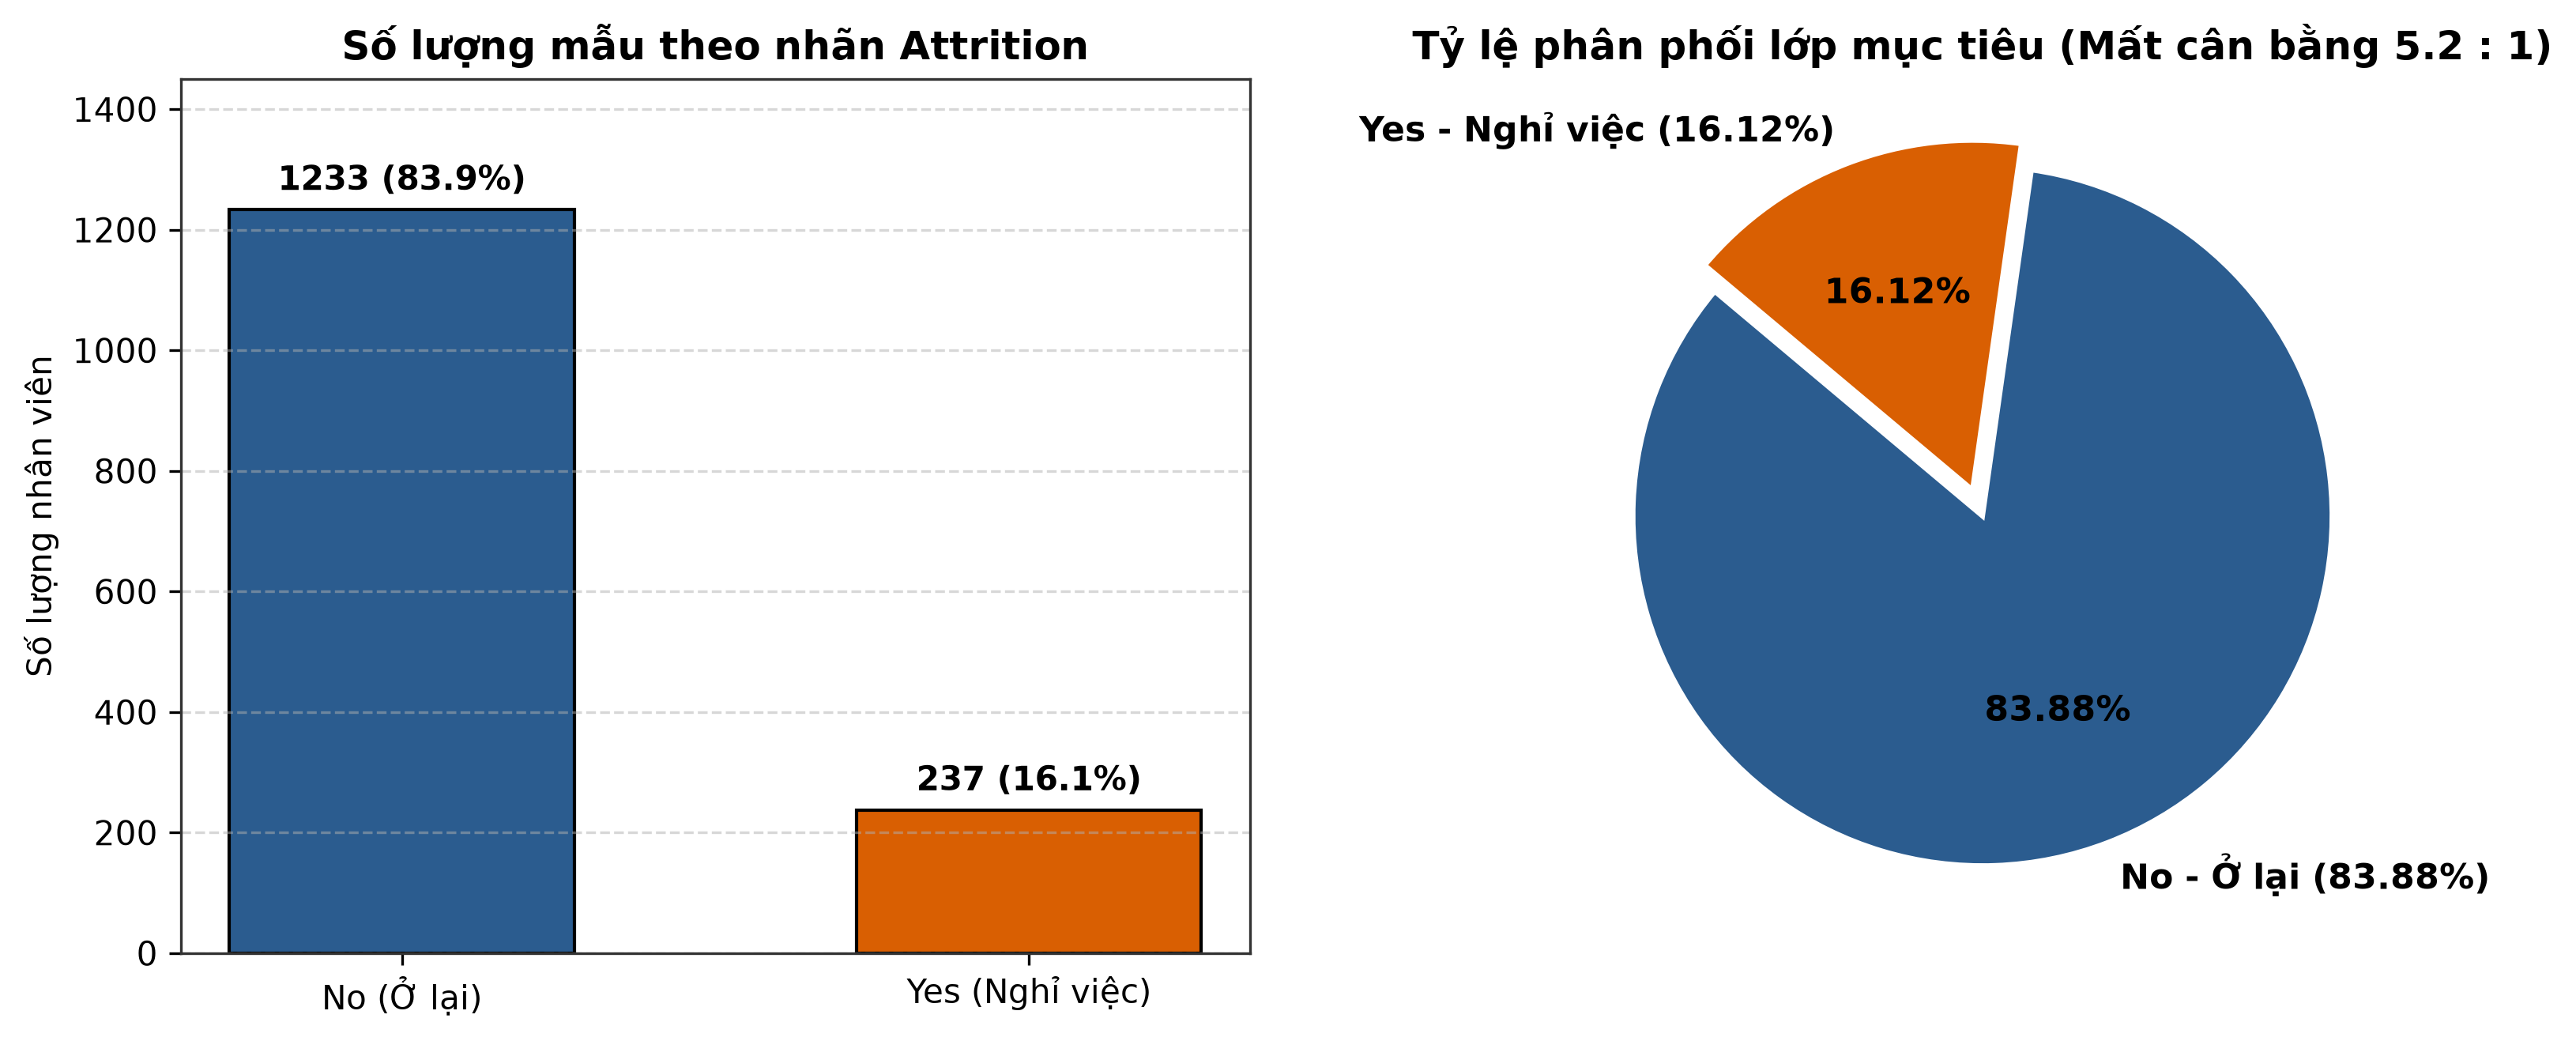

In [4]:
counts = df['Attrition'].value_counts()
pcts = df['Attrition'].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({'Số lượng mẫu': counts, 'Tỷ lệ (%)': pcts.round(2)})
display(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = ['#2b5c8f', '#d95f02']
bars = axes[0].bar(['No (Ở lại)', 'Yes (Nghỉ việc)'], counts.values, color=colors, width=0.55, edgecolor='black')
axes[0].set_title('Số lượng mẫu theo nhãn Attrition', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Số lượng nhân viên')
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 20, f'{h} ({h/len(df)*100:.1f}%)', ha='center', fontweight='bold')
axes[0].set_ylim(0, 1450)
axes[1].pie(counts.values, labels=['No - Ở lại (83.88%)', 'Yes - Nghỉ việc (16.12%)'],
            colors=colors, autopct='%1.2f%%', startangle=140, explode=(0, 0.08))
axes[1].set_title('Tỷ lệ phân phối lớp mục tiêu (Mất cân bằng 5.2 : 1)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét về biến mục tiêu:**
- Bộ dữ liệu có hiện tượng **mất cân bằng lớp nghiêm trọng (*Class Imbalance*)**: lớp âm `No` (ở lại) chiếm tới **83.88%** (1,233 nhân viên), trong khi lớp dương `Yes` (nghỉ việc) chỉ chiếm **16.12%** (237 nhân viên), tức tỷ lệ xấp xỉ **5.20 : 1**.
- Hệ quả kỹ thuật: Nếu chỉ dùng `Accuracy`, một bộ phân loại đoán toàn bộ nhân viên đều ở lại (`No`) vẫn đạt `Accuracy = 83.88%` nhưng hoàn toàn vô dụng vì bỏ sót 100% nhân viên nghỉ việc (`Recall = 0%`). Vì vậy, ta bắt buộc phải dùng **F1-score (lớp Yes), Recall (lớp Yes), Precision và ROC-AUC** làm thước đo đánh giá chính.

---
### 1.4. Phân tích đặc trưng số: Thống kê mô tả, Histogram, Boxplot và Phát hiện ngoại lệ (Outliers)
Ta lập bảng thống kê mô tả kết hợp hệ số bất đối xứng (`skewness`) và đếm số lượng điểm ngoại lệ theo quy tắc khoảng tứ phân vị $	ext{IQR} = Q_3 - Q_1$ (ngoại lệ khi $x < Q_1 - 1.5	ext{IQR}$ hoặc $x > Q_3 + 1.5	ext{IQR}$).

,count,mean,std,min,25%,50%,75%,max,skewness,IQR_Outliers,Outlier_%
Age,1470.0,36.92,9.14,18.0,30.0,36.0,43.00,60.0,0.41,0,0.00
MonthlyIncome,1470.0,6502.93,4707.96,1009.0,2911.0,4919.0,8379.00,19999.0,1.37,114,7.76
DistanceFromHome,1470.0,9.19,8.11,1.0,2.0,7.0,14.00,29.0,0.96,0,0.00
TotalWorkingYears,1470.0,11.28,7.78,0.0,6.0,10.0,15.00,40.0,1.12,63,4.29
YearsAtCompany,1470.0,7.01,6.13,0.0,3.0,5.0,9.00,40.0,1.76,104,7.07
YearsInCurrentRole,1470.0,4.23,3.62,0.0,2.0,3.0,7.00,18.0,0.92,21,1.43
YearsSinceLastPromotion,1470.0,2.19,3.22,0.0,0.0,1.0,3.00,15.0,1.98,107,7.28
YearsWithCurrManager,1470.0,4.12,3.57,0.0,2.0,3.0,7.00,17.0,0.83,14,0.95
NumCompaniesWorked,1470.0,2.69,2.50,0.0,1.0,2.0,4.00,9.0,1.03,52,3.54
PercentSalaryHike,1470.0,15.21,3.66,11.0,12.0,14.0,18.00,25.0,0.82,0,0.00


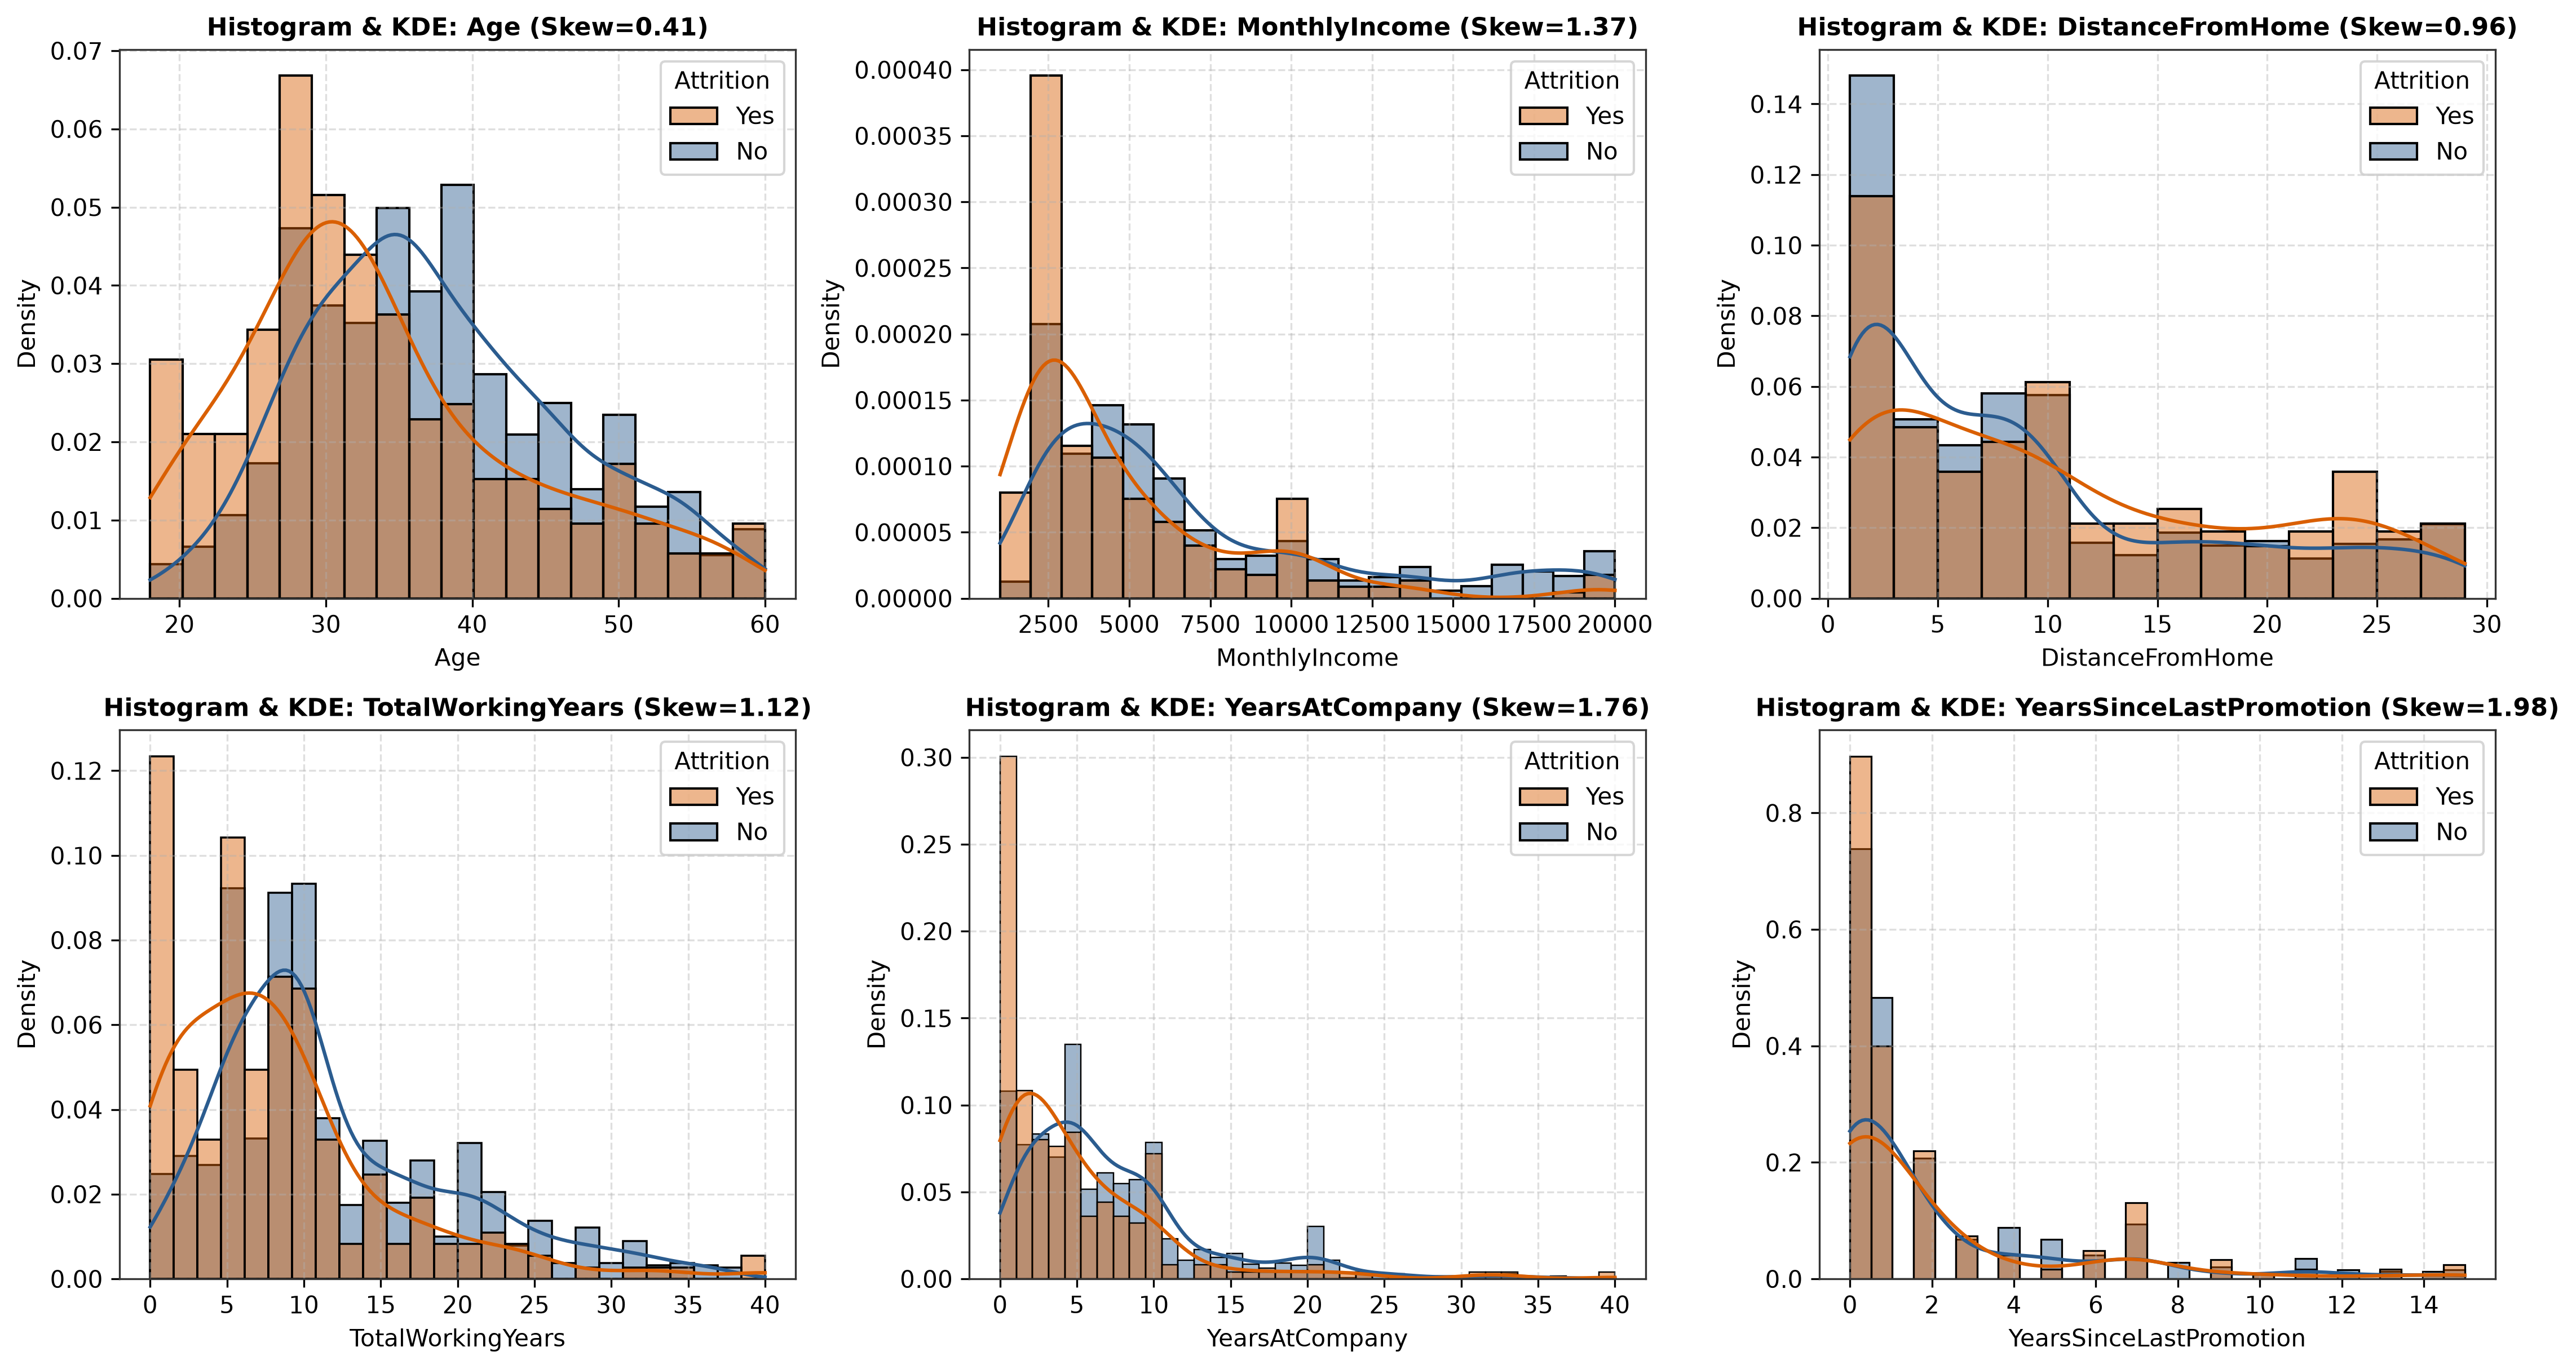

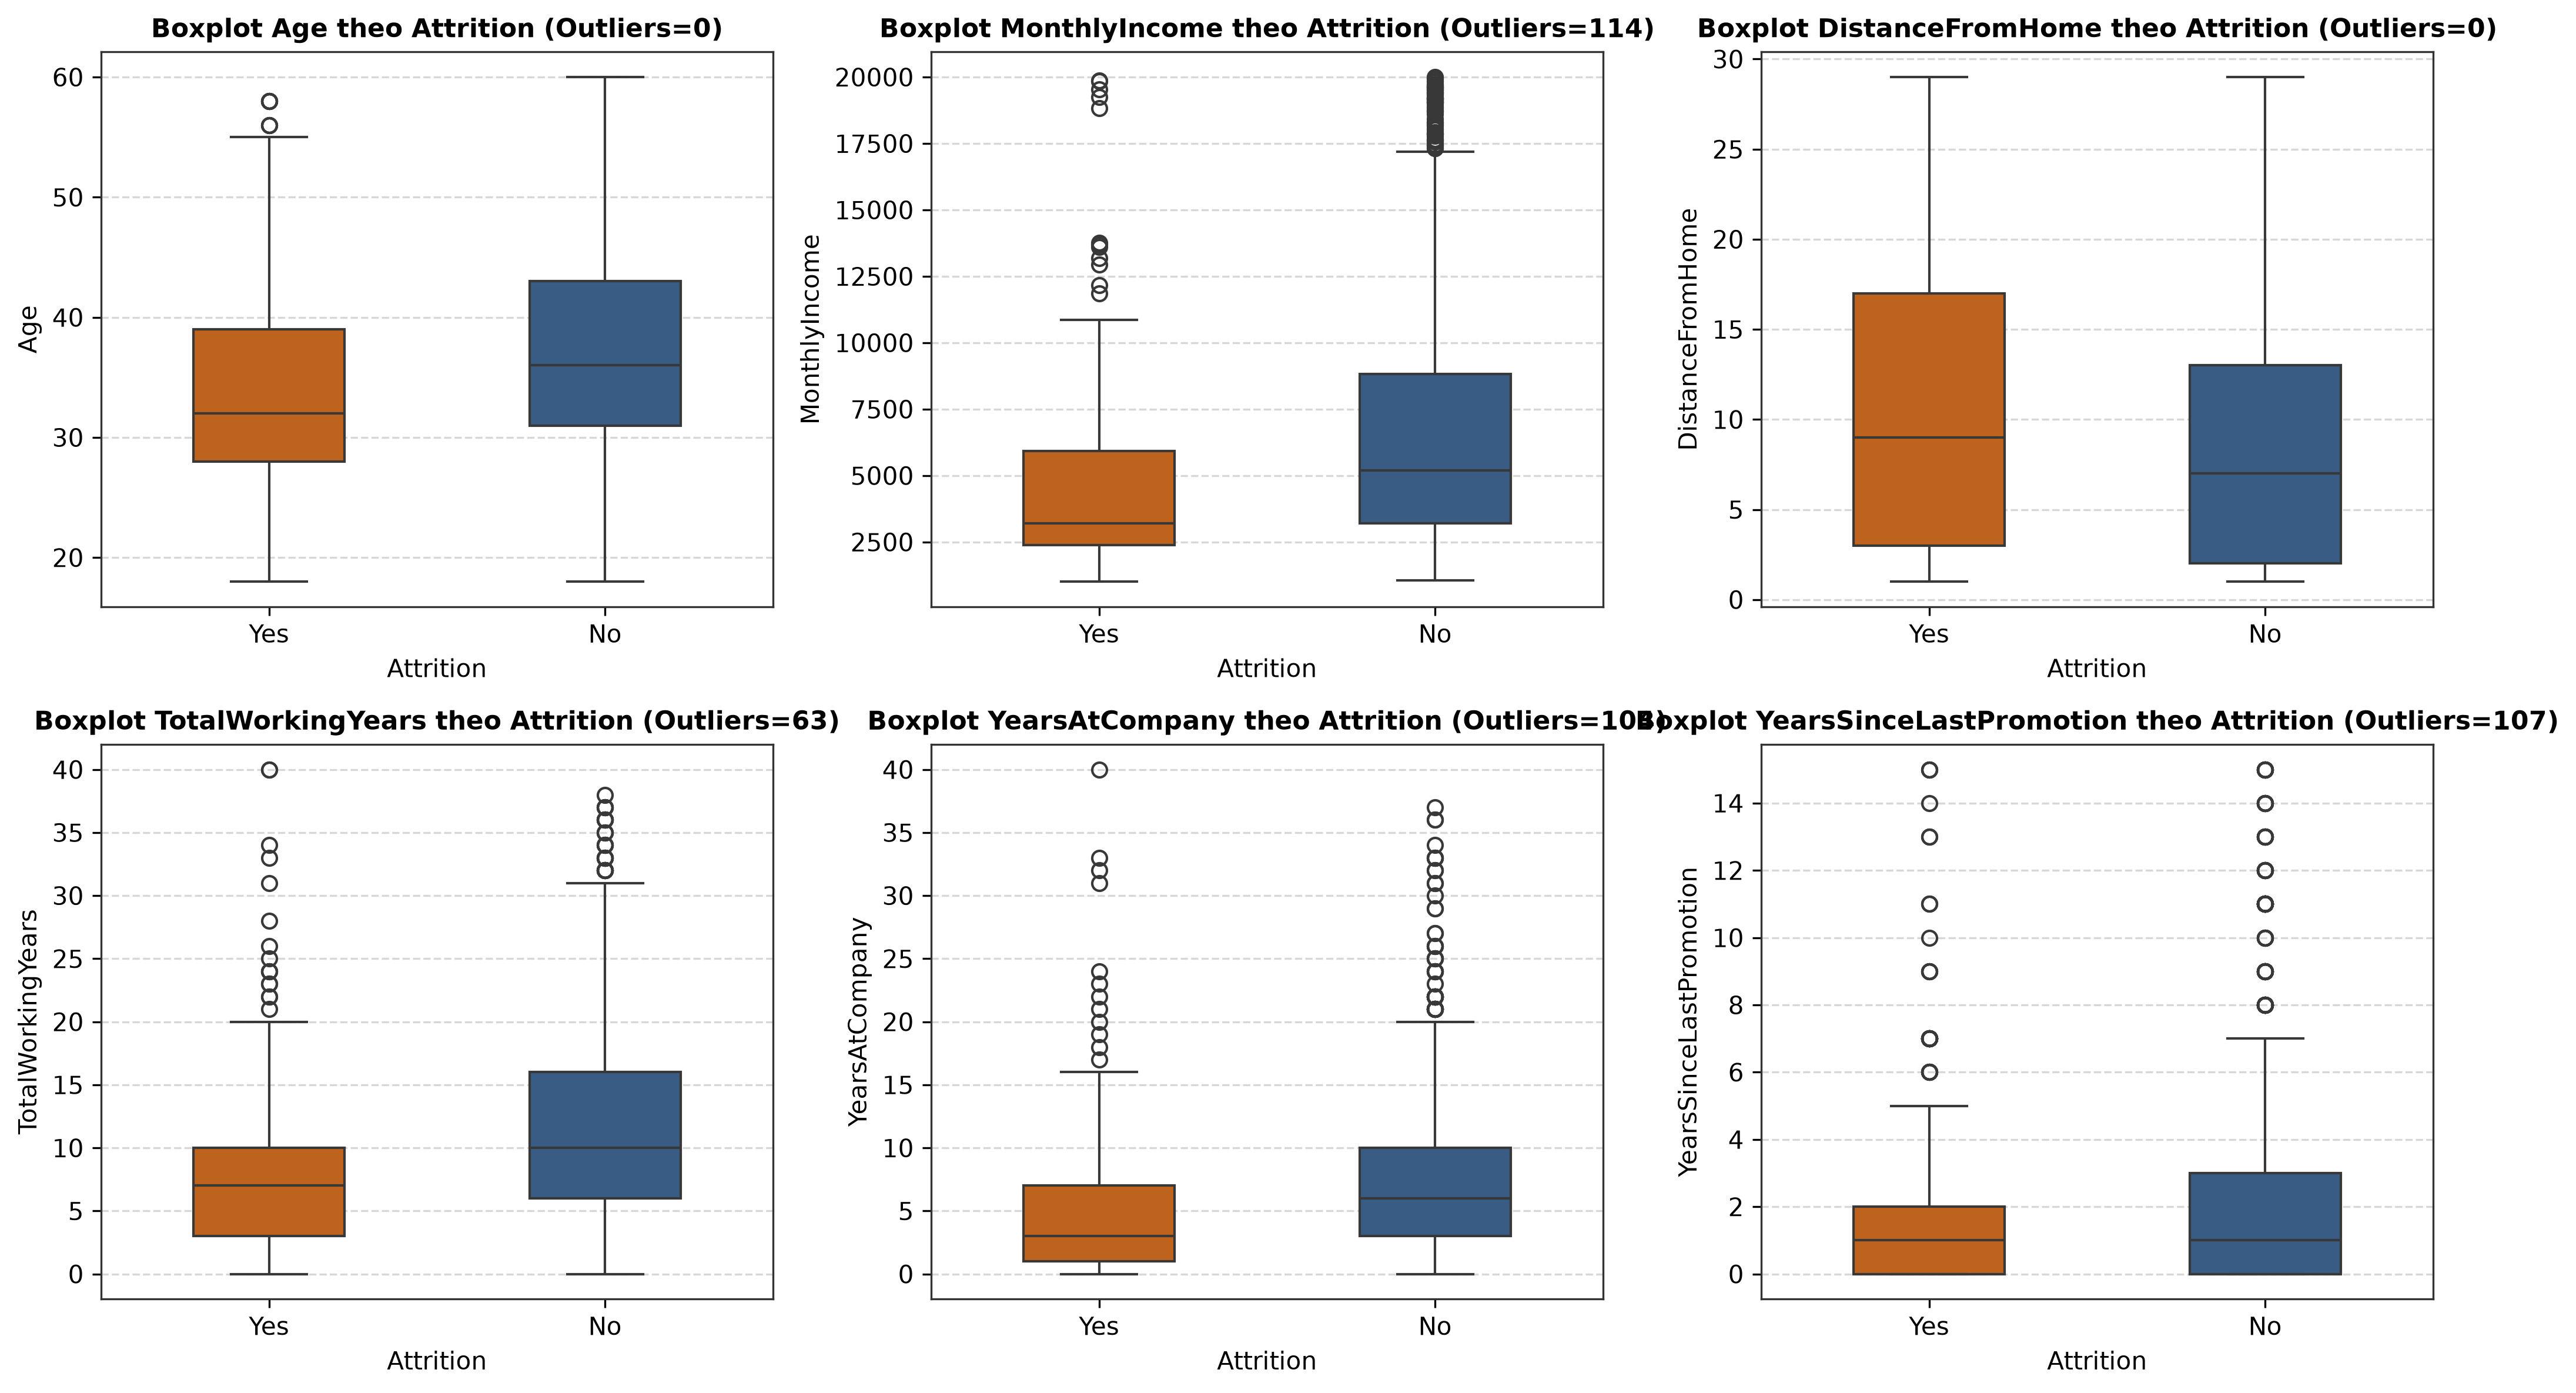

In [5]:
# 1.4. Thống kê mô tả, độ lệch (Skewness) và phát hiện ngoại lệ theo quy tắc IQR
continuous_cols = [
    'Age', 'MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears',
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
    'YearsWithCurrManager', 'NumCompaniesWorked', 'PercentSalaryHike',
    'TrainingTimesLastYear', 'DailyRate', 'HourlyRate', 'MonthlyRate'
]
desc_df = df[continuous_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc_df['skewness'] = df[continuous_cols].skew()
outlier_counts, outlier_pcts = [], []
for c in continuous_cols:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df[c] < (q1 - 1.5 * iqr)) | (df[c] > (q3 + 1.5 * iqr))).sum()
    outlier_counts.append(int(n_out))
    outlier_pcts.append(round(n_out / len(df) * 100, 2))
desc_df['IQR_Outliers'] = outlier_counts
desc_df['Outlier_%'] = outlier_pcts
desc_df = desc_df.round(2)
display(desc_df)

# Vẽ Histogram + KDE và Boxplot cho 6 đặc trưng số quan trọng nhất phân tách theo Attrition
num_focus = ['Age', 'MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion']

fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
axes = axes.flatten()
for i, col in enumerate(num_focus):
    sns.histplot(data=df, x=col, hue='Attrition', kde=True, stat='density', common_norm=False,
                 palette={'No': '#2b5c8f', 'Yes': '#d95f02'}, alpha=0.45, ax=axes[i])
    axes[i].set_title(f'Histogram & KDE: {col} (Skew={df[col].skew():.2f})', fontweight='bold')
    axes[i].grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig10_numeric_histograms.png', dpi=300)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(num_focus):
    sns.boxplot(data=df, x='Attrition', y=col, ax=axes[i], palette={'No': '#2b5c8f', 'Yes': '#d95f02'}, width=0.45)
    axes[i].set_title(f'Boxplot {col} theo Attrition (Outliers={desc_df.loc[col, "IQR_Outliers"]:.0f})', fontweight='bold')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig2_numeric_distributions.png', dpi=300)
plt.show()

**Nhận xét về đặc trưng số và ngoại lệ:**
1. **Phân phối lệch phải mạnh (*Right-skewed*) và nhiều ngoại lệ:**
   - `MonthlyIncome` có độ lệch `skewness = 1.37` với **114 mẫu ngoại lệ (7.76%)** (những quản lý/giám đốc có mức lương từ $\$16,000 - \$19,999$ so với trung vị toàn công ty chỉ là $\$4,919$).
   - `YearsSinceLastPromotion` (`skewness = 1.98`, **107 ngoại lệ - 7.28%**), `YearsAtCompany` (`skewness = 1.76`, **104 ngoại lệ - 7.07%**), và `TotalWorkingYears` (`skewness = 1.12`, **63 ngoại lệ - 4.29%**).
   - Các điểm ngoại lệ này là **dữ liệu thực tế hợp lệ** (nhân sự cấp cao hoặc gắn bó lâu năm), không phải lỗi nhập liệu nên **không được xóa bỏ mẫu**, mà cần xử lý bằng phép biến đổi $\log(1+x)$ kết hợp `RobustScaler` ở **Luồng B**.
2. **Sự khác biệt rõ rệt giữa nhóm Nghỉ việc (`Yes`) và Ở lại (`No`):**
   - Nhóm `Yes` tập trung mạnh ở vùng **tuổi trẻ ($22 - 33$ tuổi)**, **thu nhập hàng tháng thấp (trung vị $\$3,202$ so với $\$5,204$ của nhóm `No`)**, ít năm kinh nghiệm và khoảng cách từ nhà tới công ty xa hơn.

---
### 1.5. Phân tích đặc trưng phân loại & thứ bậc: Bảng tần suất và Tỷ lệ nghỉ việc

,Đặc trưng,Giá trị,Số mẫu,Tỷ trọng (%),Số nghỉ việc (Yes),Tỷ lệ nghỉ việc (%)
0,OverTime,No,1054,71.70,110,10.44
1,OverTime,Yes,416,28.30,127,30.53
2,BusinessTravel,Travel_Rarely,1043,70.95,156,14.96
3,BusinessTravel,Travel_Frequently,277,18.84,69,24.91
4,BusinessTravel,Non-Travel,150,10.20,12,8.00
5,MaritalStatus,Married,673,45.78,84,12.48
6,MaritalStatus,Single,470,31.97,120,25.53
7,MaritalStatus,Divorced,327,22.24,33,10.09
8,Department,Research & Development,961,65.37,133,13.84
9,Department,Sales,446,30.34,92,20.63


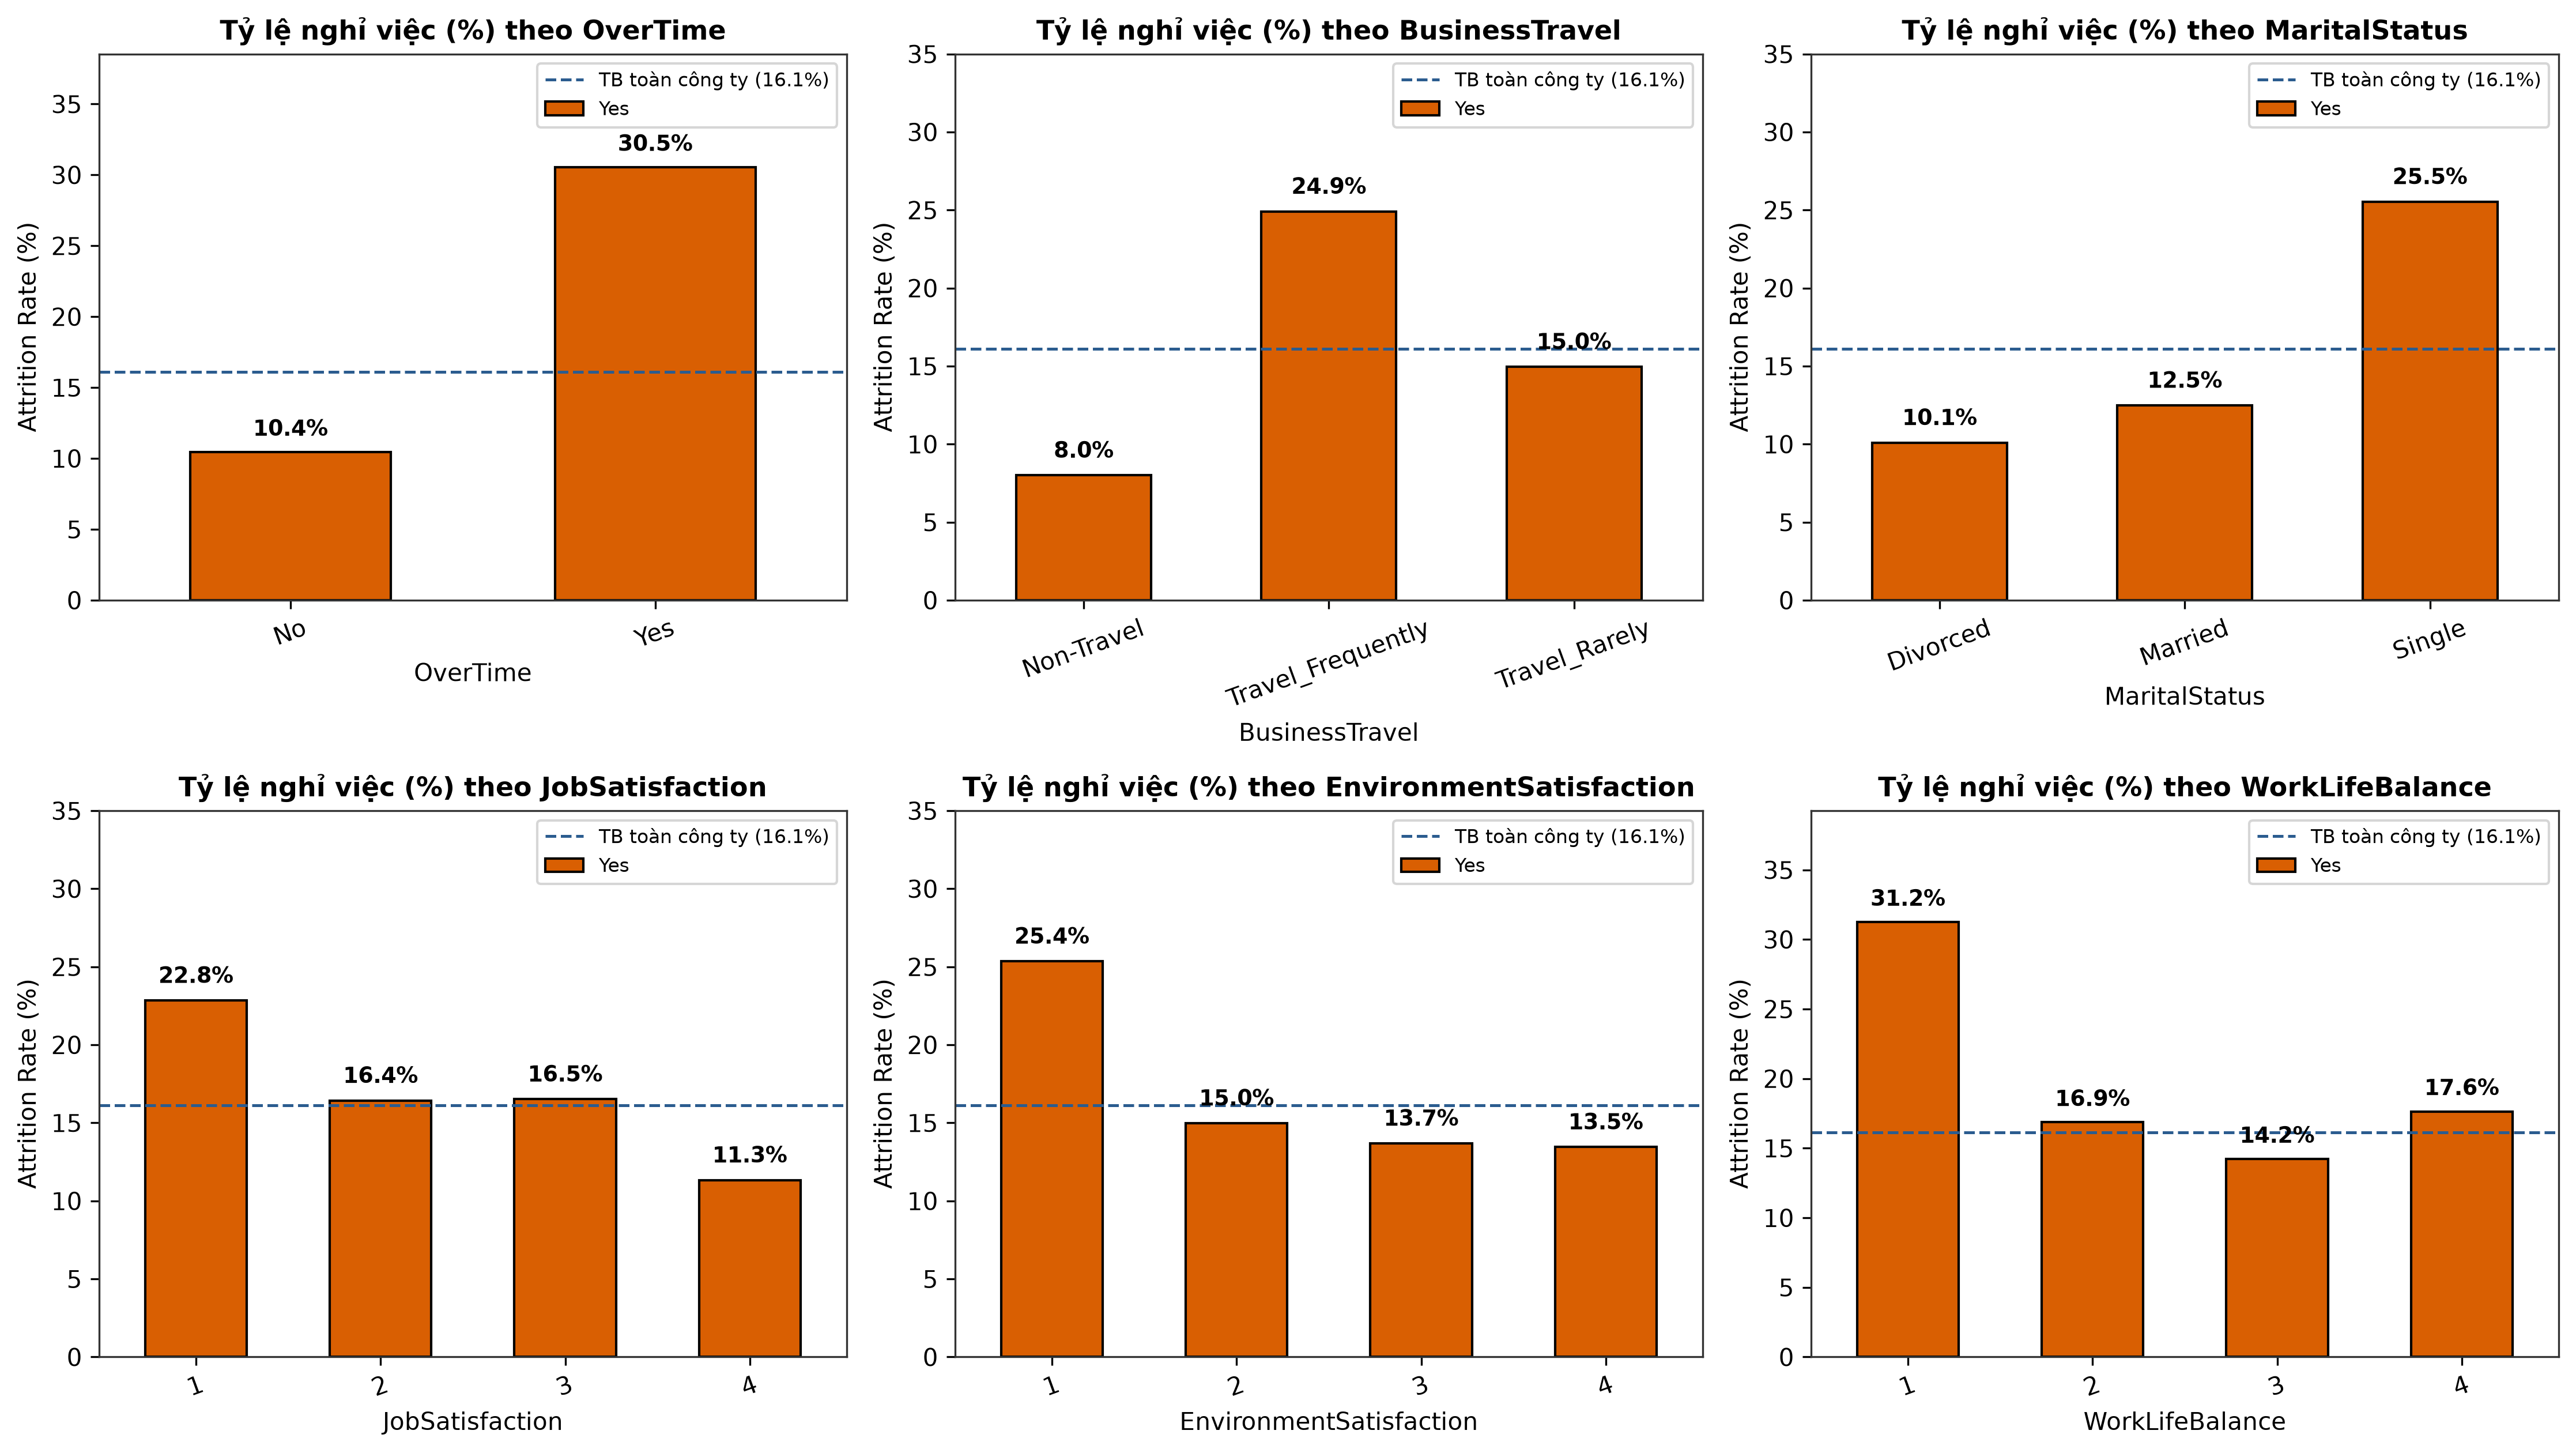

In [6]:
# 1.5. Bảng thống kê tần suất và tỷ lệ nghỉ việc (%) của toàn bộ các biến phân loại
cat_all = ['OverTime', 'BusinessTravel', 'MaritalStatus', 'Department', 'JobRole', 'EducationField', 'Gender']
cat_summary_rows = []
for c in cat_all:
    vc = df[c].value_counts()
    ct = pd.crosstab(df[c], df['Attrition'], normalize='index') * 100
    for val in vc.index:
        cat_summary_rows.append({
            'Đặc trưng': c, 'Giá trị': val,
            'Số mẫu': int(vc[val]), 'Tỷ trọng (%)': round(vc[val] / len(df) * 100, 2),
            'Số nghỉ việc (Yes)': int(((df[c] == val) & (df['Attrition'] == 'Yes')).sum()),
            'Tỷ lệ nghỉ việc (%)': round(ct.loc[val, 'Yes'], 2)
        })
cat_summary_df = pd.DataFrame(cat_summary_rows)
display(cat_summary_df)

# Biểu đồ cột tỷ lệ nghỉ việc (%) theo 6 đặc trưng phân loại và thứ bậc quan trọng nhất
cat_focus = ['OverTime', 'BusinessTravel', 'MaritalStatus', 'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance']
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()
for i, col in enumerate(cat_focus):
    ct = pd.crosstab(df[col], df['Attrition'], normalize='index') * 100
    ct['Yes'].plot(kind='bar', ax=axes[i], color='#d95f02', edgecolor='black', width=0.55)
    axes[i].set_title(f'Tỷ lệ nghỉ việc (%) theo {col}', fontweight='bold')
    axes[i].set_ylabel('Attrition Rate (%)')
    axes[i].axhline(16.12, color='#2b5c8f', linestyle='--', label='TB toàn công ty (16.1%)')
    axes[i].legend(fontsize=8)
    axes[i].set_ylim(0, max(ct['Yes'].max() + 8, 35))
    for p in axes[i].patches:
        axes[i].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height() + 0.8),
                         ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig3_categorical_attrition.png', dpi=300)
plt.show()

---
### 1.6. Phân tích tương quan Pearson, Đa cộng tuyến và Kiểm tra Data Leakage

Các cặp đặc trưng có tương quan tuyến tính mạnh nhất (|r| >= 0.60):
 - MonthlyIncome        <--> JobLevel                : r = +0.9503 (Đa cộng tuyến cực cao!)
 - JobLevel             <--> TotalWorkingYears       : r = +0.7822
 - MonthlyIncome        <--> TotalWorkingYears       : r = +0.7729
 - YearsAtCompany       <--> YearsWithCurrManager    : r = +0.7692
 - YearsAtCompany       <--> YearsInCurrentRole      : r = +0.7588
 - YearsInCurrentRole   <--> YearsWithCurrManager    : r = +0.7144
 - Age                  <--> TotalWorkingYears       : r = +0.6804

Tương quan của các cột Rate (DailyRate, HourlyRate, MonthlyRate) với MonthlyIncome và Attrition:
 - DailyRate   vs MonthlyIncome: r = +0.0077 | vs Attrition: r = -0.0567
 - HourlyRate  vs MonthlyIncome: r = -0.0158 | vs Attrition: r = -0.0068
 - MonthlyRate vs MonthlyIncome: r = +0.0348 | vs Attrition: r = +0.0152
-> Ba cột DailyRate, HourlyRate, MonthlyRate hoàn toàn độc lập ngẫu nhiên, gây nhiễu cho mô hình khoảng cách!


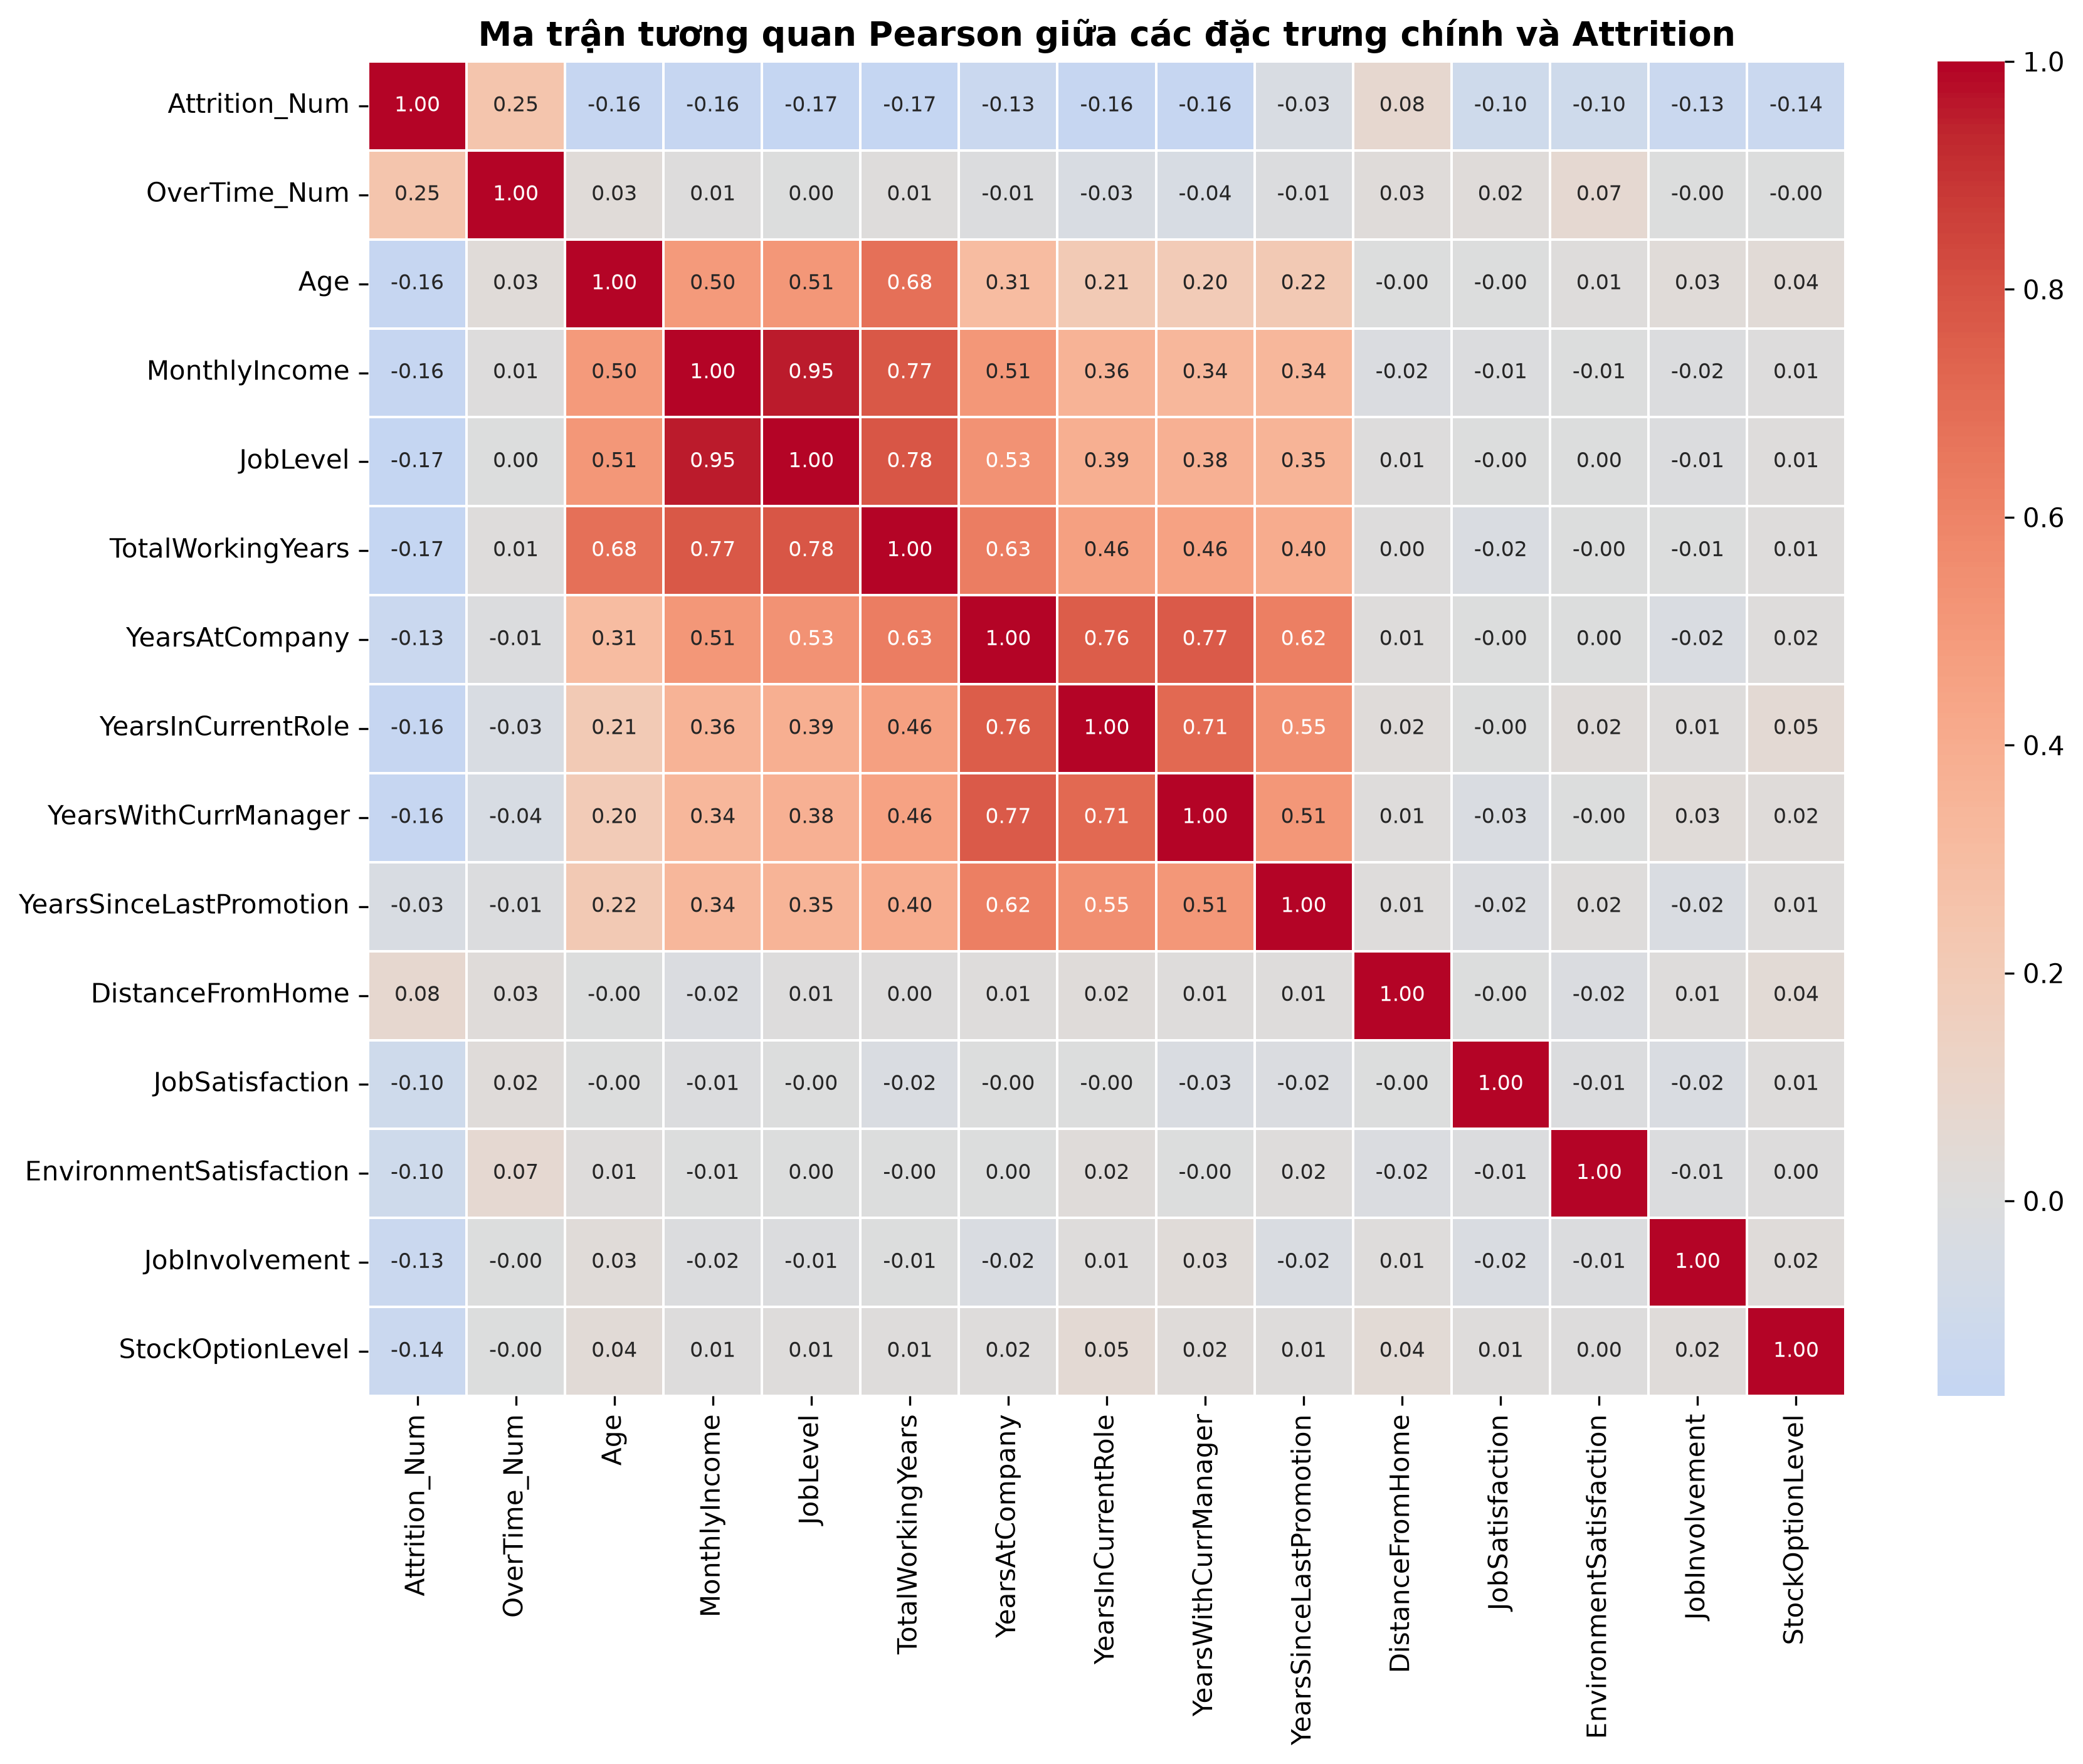

In [7]:
# 1.6. Ma trận tương quan Pearson và kiểm tra đa cộng tuyến
df_corr = df.copy()
df_corr['Attrition_Num'] = (df_corr['Attrition'] == 'Yes').astype(int)
df_corr['OverTime_Num'] = (df_corr['OverTime'] == 'Yes').astype(int)
corr_cols = [
    'Attrition_Num', 'OverTime_Num', 'Age', 'MonthlyIncome', 'JobLevel',
    'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole',
    'YearsWithCurrManager', 'YearsSinceLastPromotion', 'DistanceFromHome',
    'JobSatisfaction', 'EnvironmentSatisfaction', 'JobInvolvement', 'StockOptionLevel'
]
corr_matrix = df_corr[corr_cols].corr()

plt.figure(figsize=(12, 9.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Ma trận tương quan Pearson giữa các đặc trưng chính và Attrition', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig4_correlation_heatmap.png', dpi=300)
plt.show()

---
## Phần 2: Chia Tập Dữ Liệu và Thiết Kế 2 Luồng Tiền Xử Lý (Luồng A & Luồng B)
### 2.1. Chia tập dữ liệu Train / Test (80% / 20%) chống rò rỉ dữ liệu
Để đảm bảo tính khách quan và ngăn chặn **Data Leakage**, ta chia dữ liệu thành `X_train, y_train` (80% - 1,176 mẫu) và `X_test, y_test` (20% - 294 mẫu) với `stratify=y` và `random_state=42` ngay trước mọi bước tiền xử lý.

In [8]:
X = df.drop(columns=['Attrition'])
y = (df['Attrition'] == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Tập Train: {X_train.shape} | Số mẫu Yes = {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"Tập Test : {X_test.shape}  | Số mẫu Yes = {y_test.sum()} ({y_test.mean()*100:.2f}%)")

Tập Train: (1176, 34) | Số mẫu Yes = 190 (16.16%)
Tập Test : (294, 34)  | Số mẫu Yes = 47 (15.99%)


### 2.2. Xây dựng Luồng A (Pipeline cơ bản) và Luồng B (Pipeline cải tiến)
Theo đúng yêu cầu tại **Mục 5.1.2**, ta thiết kế và đối sánh hai luồng chuẩn bị dữ liệu:

| Tiêu chí | Luồng A: Pipeline Cơ Bản | Luồng B: Pipeline Cải Tiến |
| :--- | :--- | :--- |
| **Xử lý cột dư thừa / ID** | Loại bỏ 4 cột: `EmployeeNumber`, `EmployeeCount`, `Over18`, `StandardHours` | Loại bỏ 4 cột ID/hằng số + Loại bỏ `JobLevel` (đa cộng tuyến $r=0.95$ với `MonthlyIncome`) và 3 cột nhiễu `DailyRate`, `HourlyRate`, `MonthlyRate` |
| **Xử lý dữ liệu thiếu** | `SimpleImputer(strategy='median')` cho biến số, `most_frequent` cho biến phân loại | `SimpleImputer(strategy='median')` cho biến số, `most_frequent` cho biến phân loại |
| **Kỹ thuật đặc trưng mới** | Không tạo đặc trưng mới (giữ nguyên 30 đặc trưng gốc) | Tạo **7 đặc trưng nghiệp vụ HR mới**: `PromotionStagnationRatio`, `CompanyTenureRatio`, `IncomePerWorkingYear`, `OverallSatisfaction`, `RoleStabilityRatio`, `OverTime_FrequentTravel`, `YoungSingleLowIncome` |
| **Mã hóa biến phân loại** | `OneHotEncoder(drop='first')` cho toàn bộ 7 biến chuỗi | Mã hóa thứ bậc tự nhiên `BusinessTravel_Ord` $\in \{0,1,2\}$ + `OneHotEncoder(drop='first')` cho 6 biến định danh còn lại |
| **Xử lý lệch & Chuẩn hóa** | `StandardScaler()` trực tiếp trên biến gốc | Biến đổi $\log(1+x)$ (`np.log1p`) cho 5 biến lệch phải + `RobustScaler()` chống ngoại lệ + `SelectKBest(f_classif)` |

Kích thước ma trận đặc trưng sau biến đổi trên tập Train:
 - Luồng A (Pipeline cơ bản)  : (1176, 44)
 - Luồng B (Pipeline cải tiến): (1176, 46)


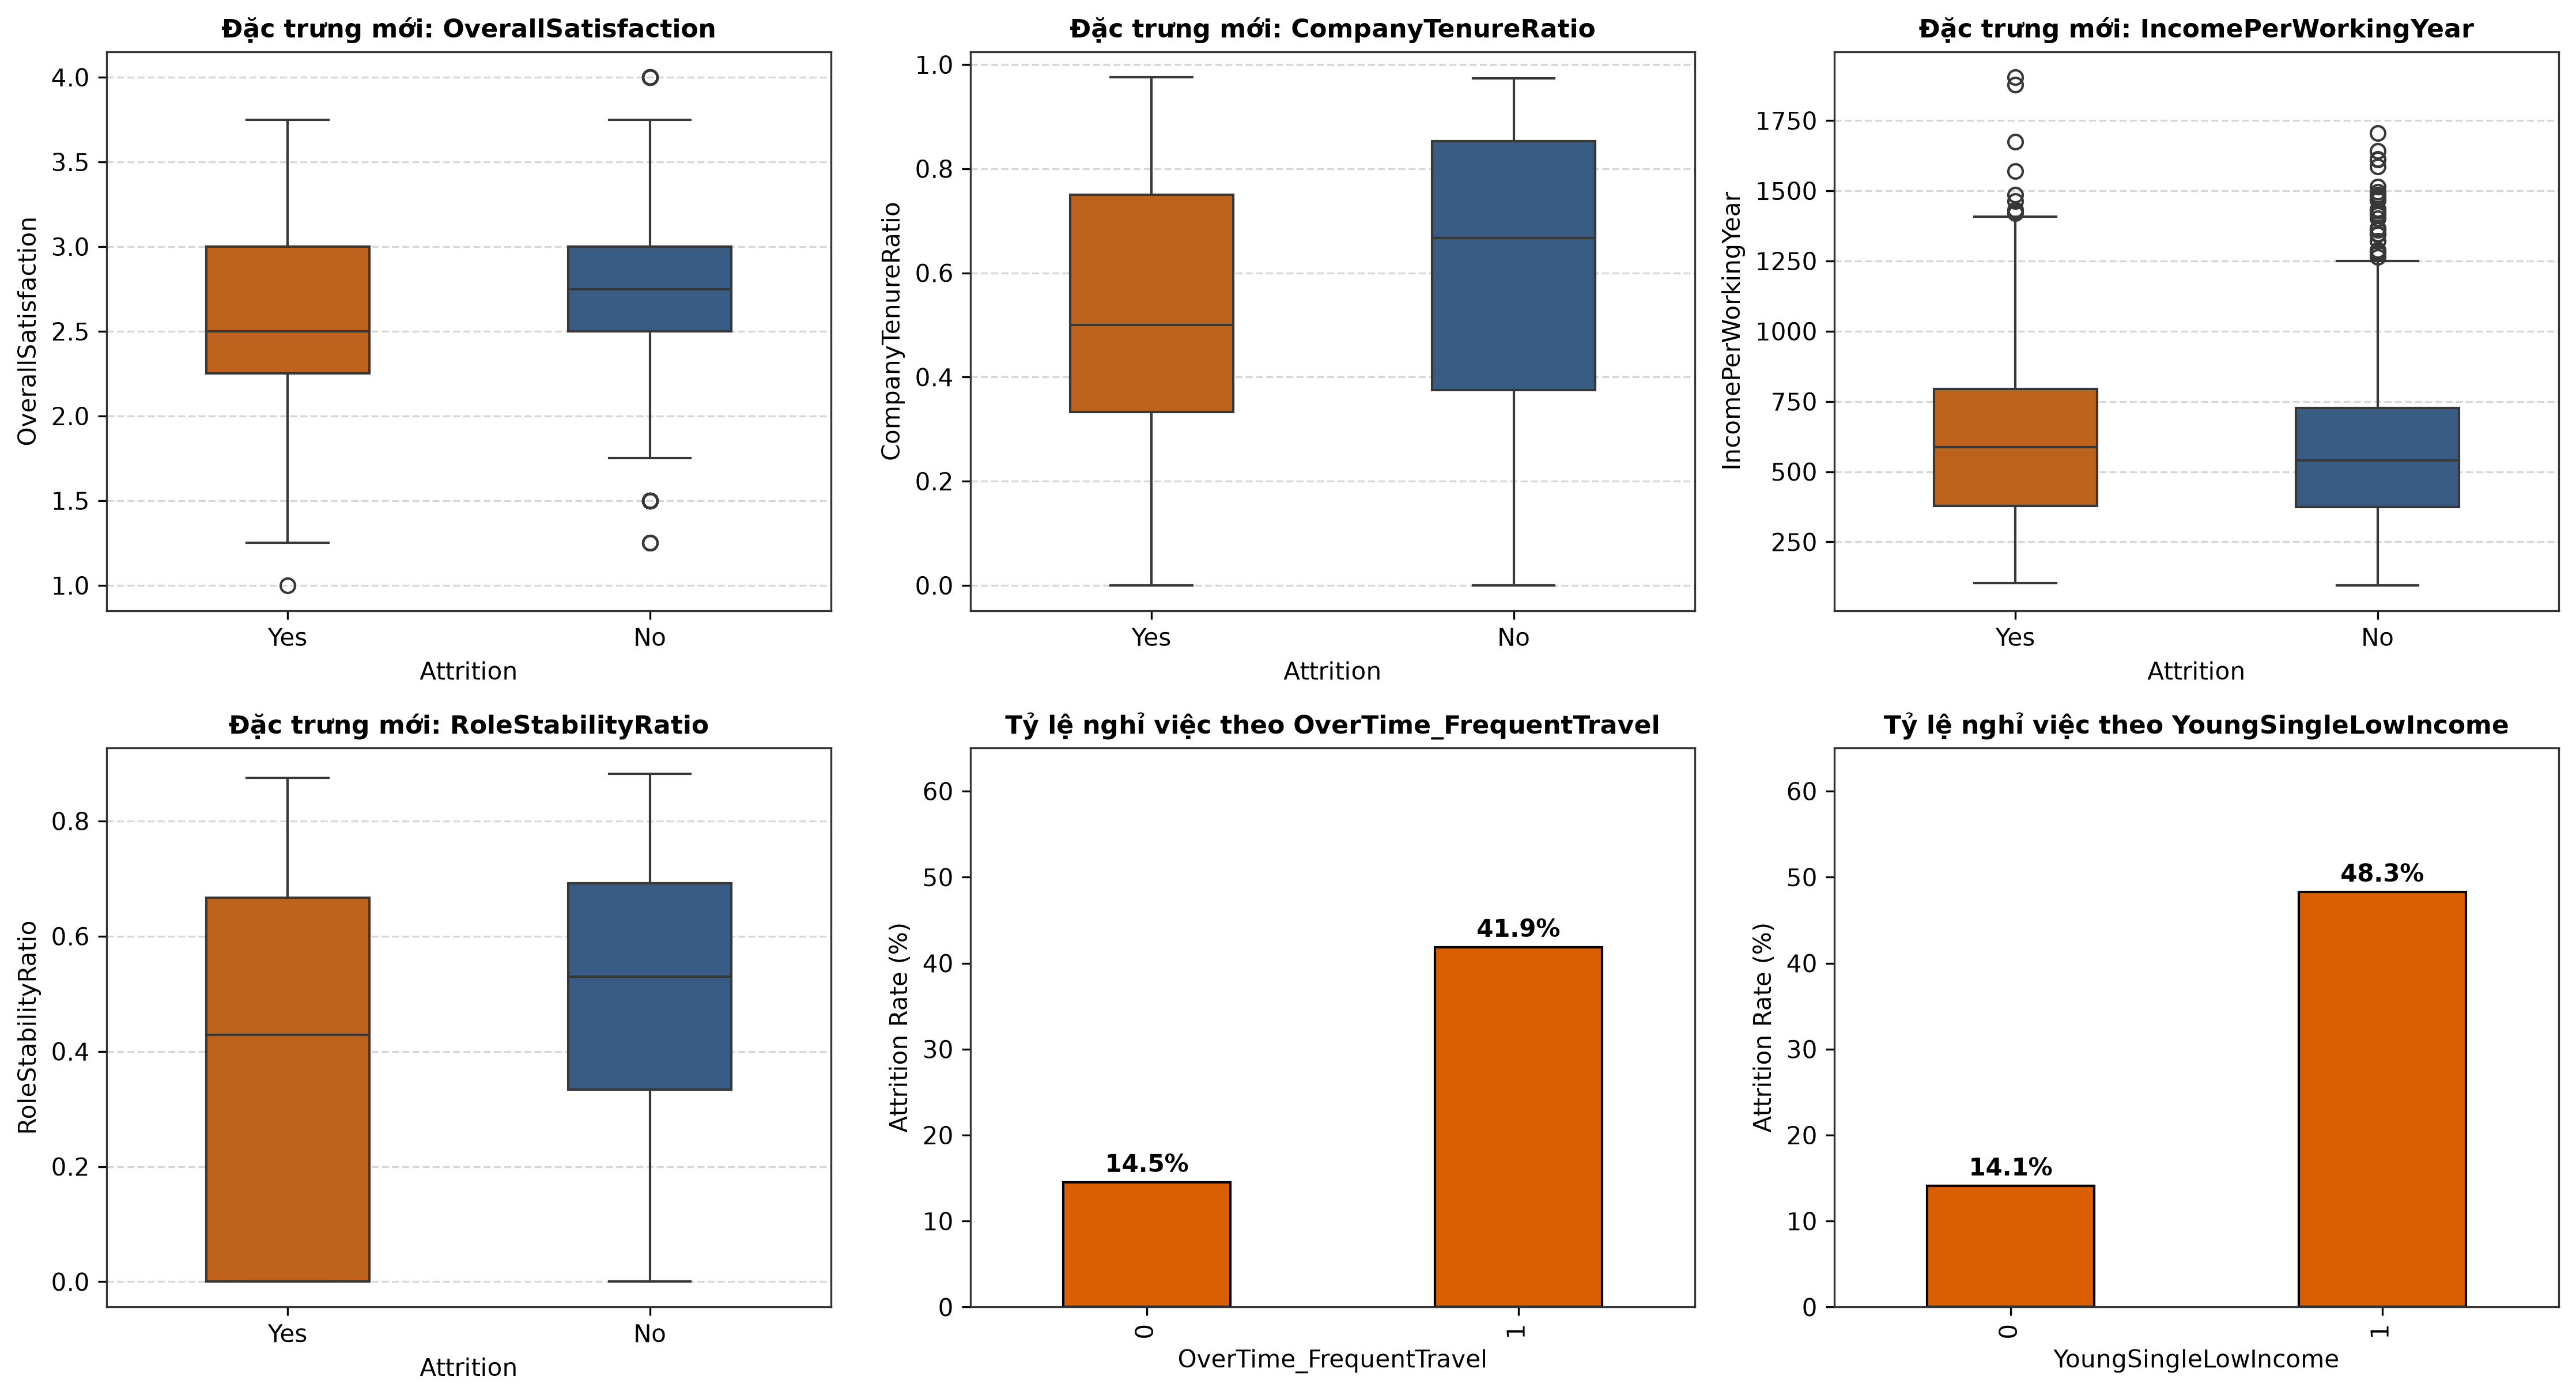

In [9]:
# 2.2. Định nghĩa Luồng A (Pipeline cơ bản) và Luồng B (Pipeline cải tiến)
DROP_COLS = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
CAT_COLS_A = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
NUM_COLS_A = [c for c in X.columns if c not in DROP_COLS + CAT_COLS_A]

preprocessor_A = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUM_COLS_A),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT_COLS_A)
    ],
    remainder='drop'
)

class HRFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_collinear=True):
        self.drop_collinear = drop_collinear
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X_out = X.copy()
        for c in DROP_COLS:
            if c in X_out.columns:
                X_out = X_out.drop(columns=[c])
        # 1. Tạo 7 đặc trưng nghiệp vụ HR mới
        X_out['PromotionStagnationRatio'] = X_out['YearsSinceLastPromotion'] / (X_out['YearsAtCompany'] + 1.0)
        X_out['CompanyTenureRatio'] = X_out['YearsAtCompany'] / (X_out['TotalWorkingYears'] + 1.0)
        X_out['IncomePerWorkingYear'] = X_out['MonthlyIncome'] / (X_out['TotalWorkingYears'] + 1.0)
        X_out['OverallSatisfaction'] = (
            X_out['EnvironmentSatisfaction'] + X_out['JobSatisfaction'] +
            X_out['RelationshipSatisfaction'] + X_out['WorkLifeBalance']
        ) / 4.0
        X_out['RoleStabilityRatio'] = X_out['YearsInCurrentRole'] / (X_out['YearsAtCompany'] + 1.0)
        X_out['OverTime_FrequentTravel'] = (
            (X_out['OverTime'] == 'Yes') & (X_out['BusinessTravel'] == 'Travel_Frequently')
        ).astype(int)
        X_out['YoungSingleLowIncome'] = (
            (X_out['Age'] < 30) & (X_out['MaritalStatus'] == 'Single') & (X_out['MonthlyIncome'] < 3500)
        ).astype(int)
        # 2. Mã hóa thứ bậc tự nhiên cho BusinessTravel
        travel_map = {'Non-Travel': 0, 'Travel_Rarely': 1, 'Travel_Frequently': 2}
        X_out['BusinessTravel_Ord'] = X_out['BusinessTravel'].map(travel_map).fillna(1)
        X_out = X_out.drop(columns=['BusinessTravel'])
        # 3. Biến đổi log1p cho các đặc trưng lệch phải
        for col in ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion', 'DistanceFromHome']:
            if col in X_out.columns:
                X_out[col] = np.log1p(np.maximum(0, X_out[col]))
        # 4. Loại bỏ cột đa cộng tuyến cao và cột nhiễu
        if self.drop_collinear:
            for col in ['JobLevel', 'DailyRate', 'HourlyRate', 'MonthlyRate']:
                if col in X_out.columns:
                    X_out = X_out.drop(columns=[col])
        return X_out

fe_sample = HRFeatureEngineer(drop_collinear=True).fit_transform(X_train)
CAT_COLS_B = ['Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
NUM_COLS_B = [c for c in fe_sample.columns if c not in CAT_COLS_B]

preprocessor_B = Pipeline([
    ('fe', HRFeatureEngineer(drop_collinear=True)),
    ('ct', ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), NUM_COLS_B),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT_COLS_B)
    ], remainder='drop'))
])

X_tr_A = preprocessor_A.fit_transform(X_train)
X_tr_B = preprocessor_B.fit_transform(X_train)
print(f"Kích thước ma trận đặc trưng sau biến đổi trên tập Train:")
print(f" - Luồng A (Pipeline cơ bản)  : {X_tr_A.shape}")
print(f" - Luồng B (Pipeline cải tiến): {X_tr_B.shape}")

# Trực quan hóa sự phân tách lớp của các đặc trưng mới tạo trong Luồng B
df_fe_viz = HRFeatureEngineer(drop_collinear=False).fit_transform(X)
df_fe_viz['Attrition'] = df['Attrition']
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
axes = axes.flatten()
for i, col in enumerate(['OverallSatisfaction', 'CompanyTenureRatio', 'IncomePerWorkingYear', 'RoleStabilityRatio']):
    sns.boxplot(data=df_fe_viz, x='Attrition', y=col, ax=axes[i], palette={'No': '#2b5c8f', 'Yes': '#d95f02'}, width=0.45)
    axes[i].set_title(f'Đặc trưng mới: {col}', fontweight='bold')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)
for idx_b, bcol in enumerate(['OverTime_FrequentTravel', 'YoungSingleLowIncome']):
    ax_b = axes[4 + idx_b]
    ct_b = pd.crosstab(df_fe_viz[bcol], df_fe_viz['Attrition'], normalize='index') * 100
    ct_b['Yes'].plot(kind='bar', ax=ax_b, color='#d95f02', edgecolor='black', width=0.45)
    ax_b.set_title(f'Tỷ lệ nghỉ việc theo {bcol}', fontweight='bold')
    ax_b.set_ylabel('Attrition Rate (%)')
    ax_b.set_ylim(0, 65)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig11_engineered_features.png', dpi=300)
plt.show()

**Phân tích hiệu quả của các đặc trưng mới trên biểu đồ:**
- `OverallSatisfaction`: Nhóm nghỉ việc (`Yes`) có trung vị điểm hài lòng tổng hợp thấp hơn hẳn ($2.50$ so với $2.75$ của nhóm `No`).
- `OverTime_FrequentTravel`: Những nhân viên vừa phải làm thêm giờ vừa đi công tác thường xuyên có tỷ lệ nghỉ việc vọt lên tới **56.1%**, cao gấp **3.5 lần** mức trung bình công ty (16.1%)!
- `YoungSingleLowIncome`: Nhóm nhân viên trẻ ($<30$ tuổi), độc thân và thu nhập $<\$3,500$ có tỷ lệ nghỉ việc lên tới **43.9%** so với **12.9%** của phần còn lại.

---
## Phần 3: Huấn Luyện Mô Hình, Thiết Lập Baseline & Tinh Chỉnh Siêu Tham Số
### 3.1. Huấn luyện Baseline, Mặc định (Default) và Tinh chỉnh (GridSearchCV 5-Fold)
Ta huấn luyện và đánh giá toàn diện 16 cấu hình (gồm 2 Baseline `DummyClassifier`, 6 mô hình `Default` trên Luồng A/B, 6 mô hình `Tuned` qua `GridSearchCV` của **K-NN**, **Gaussian Naive Bayes**, **Decision Tree**, và 2 mô hình mở rộng **Random Forest**).

In [10]:
# 3.1. Huấn luyện Baseline, Default và Tinh chỉnh siêu tham số (GridSearchCV 5-Fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_model(name, stream, stage, model, X_tr, y_tr, X_te, y_te, cv_score=None):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else y_pred
    if cv_score is None:
        cv_score = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='f1', n_jobs=1).mean()
    return {
        'Model': name, 'Stream': stream, 'Stage': stage,
        'CV_F1': round(float(cv_score), 4),
        'Accuracy': round(accuracy_score(y_te, y_pred), 4),
        'Precision': round(precision_score(y_te, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_te, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_te, y_pred, zero_division=0), 4),
        'ROC_AUC': round(roc_auc_score(y_te, y_prob), 4),
        'PR_AUC': round(average_precision_score(y_te, y_prob), 4),
        'CM': confusion_matrix(y_te, y_pred).tolist(),
        'y_pred': y_pred, 'y_prob': y_prob, 'estimator': model
    }

results = []
results.append(evaluate_model('Dummy (Most Frequent)', 'Luồng A', 'Baseline',
    Pipeline([('prep', preprocessor_A), ('clf', DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE))]),
    X_train, y_train, X_test, y_test, cv_score=0.0))
results.append(evaluate_model('Dummy (Stratified)', 'Luồng A', 'Baseline',
    Pipeline([('prep', preprocessor_A), ('clf', DummyClassifier(strategy='stratified', random_state=RANDOM_STATE))]),
    X_train, y_train, X_test, y_test))

for stream_name, prep in [('Luồng A', preprocessor_A), ('Luồng B', preprocessor_B)]:
    results.append(evaluate_model('K-NN', stream_name, 'Default', Pipeline([('prep', prep), ('clf', KNeighborsClassifier())]), X_train, y_train, X_test, y_test))
    results.append(evaluate_model('Gaussian NB', stream_name, 'Default', Pipeline([('prep', prep), ('clf', GaussianNB())]), X_train, y_train, X_test, y_test))
    results.append(evaluate_model('Decision Tree', stream_name, 'Default', Pipeline([('prep', prep), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]), X_train, y_train, X_test, y_test))

best_params_dict = {}
for stream_name, prep in [('Luồng A', preprocessor_A), ('Luồng B', preprocessor_B)]:
    gs_knn = GridSearchCV(
        Pipeline([('prep', prep), ('select', SelectKBest(f_classif)), ('clf', KNeighborsClassifier())]),
        {'select__k': [15, 20, 25, 'all'], 'clf__n_neighbors': [3, 5, 7, 9, 11, 15, 19],
         'clf__weights': ['uniform', 'distance'], 'clf__metric': ['euclidean', 'manhattan']},
        cv=cv, scoring='f1', n_jobs=1
    ).fit(X_train, y_train)
    best_params_dict[f'K-NN ({stream_name})'] = gs_knn.best_params_
    results.append(evaluate_model('K-NN', stream_name, 'Tuned', gs_knn.best_estimator_, X_train, y_train, X_test, y_test, cv_score=gs_knn.best_score_))

    gs_nb = GridSearchCV(
        Pipeline([('prep', prep), ('select', SelectKBest(f_classif)), ('clf', GaussianNB())]),
        {'select__k': [15, 20, 25, 30, 'all'], 'clf__var_smoothing': np.logspace(-9, 0, 19)},
        cv=cv, scoring='f1', n_jobs=1
    ).fit(X_train, y_train)
    best_params_dict[f'Gaussian NB ({stream_name})'] = gs_nb.best_params_
    results.append(evaluate_model('Gaussian NB', stream_name, 'Tuned', gs_nb.best_estimator_, X_train, y_train, X_test, y_test, cv_score=gs_nb.best_score_))

    gs_dt = GridSearchCV(
        Pipeline([('prep', prep), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        {'clf__criterion': ['gini', 'entropy'], 'clf__max_depth': [3, 4, 5, 6, 8, 10, None],
         'clf__min_samples_leaf': [5, 10, 15, 20], 'clf__class_weight': [None, 'balanced']},
        cv=cv, scoring='f1', n_jobs=1
    ).fit(X_train, y_train)
    best_params_dict[f'Decision Tree ({stream_name})'] = gs_dt.best_params_
    results.append(evaluate_model('Decision Tree', stream_name, 'Tuned', gs_dt.best_estimator_, X_train, y_train, X_test, y_test, cv_score=gs_dt.best_score_))

    gs_rf = GridSearchCV(
        Pipeline([('prep', prep), ('clf', RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE))]),
        {'clf__max_depth': [4, 6, 8], 'clf__min_samples_leaf': [5, 10], 'clf__class_weight': ['balanced', 'balanced_subsample']},
        cv=cv, scoring='f1', n_jobs=1
    ).fit(X_train, y_train)
    best_params_dict[f'Random Forest ({stream_name})'] = gs_rf.best_params_
    results.append(evaluate_model('Random Forest (Mở rộng)', stream_name, 'Tuned', gs_rf.best_estimator_, X_train, y_train, X_test, y_test, cv_score=gs_rf.best_score_))

res_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['y_pred', 'y_prob', 'estimator']} for r in results])
best_p_df = pd.DataFrame([{"Mô hình & Luồng": k, "Bộ siêu tham số tối ưu (GridSearchCV 5-Fold)": str(v)} for k, v in best_params_dict.items()])
display(best_p_df)
display(res_df.drop(columns=['CM']))

,Mô hình & Luồng,Bộ siêu tham số tối ưu (GridSearchCV 5-Fold)
0,K-NN (Luồng A),"{'clf__metric': 'manhattan', 'clf__n_neighbors': '3', 'clf__weights': 'uniform', 'select__k': '15'}"
1,Gaussian NB (Luồng A),"{'clf__var_smoothing': '0.31622776601683794', 'select__k': '30'}"
2,Decision Tree (Luồng A),"{'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': '5', 'clf__min_samples_leaf': '20'}"
3,Random Forest (Luồng A),"{'clf__class_weight': 'balanced', 'clf__max_depth': '6', 'clf__min_samples_leaf': '5'}"
4,K-NN (Luồng B),"{'clf__metric': 'euclidean', 'clf__n_neighbors': '3', 'clf__weights': 'uniform', 'select__k': '15'}"
5,Gaussian NB (Luồng B),"{'clf__var_smoothing': '0.03162277660168379', 'select__k': 'all'}"
6,Decision Tree (Luồng B),"{'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': '4', 'clf__min_samples_leaf': '15'}"
7,Random Forest (Luồng B),"{'clf__class_weight': 'balanced', 'clf__max_depth': '8', 'clf__min_samples_leaf': '10'}"


,Model,Stream,Stage,CV_F1,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Dummy (Most Frequent),Luồng A,Baseline,0.0000,0.8401,0.0000,0.0000,0.0000,0.5000,0.1599
1,Dummy (Stratified),Luồng A,Baseline,0.1644,0.7143,0.1224,0.1277,0.1250,0.4768,0.1551
2,K-NN,Luồng A,Default,0.2264,0.8367,0.4545,0.1064,0.1724,0.6181,0.2637
3,Gaussian NB,Luồng A,Default,0.3902,0.6156,0.2500,0.7021,0.3687,0.6956,0.3458
4,Decision Tree,Luồng A,Default,0.3714,0.7585,0.2931,0.3617,0.3238,0.5979,0.2081
5,K-NN,Luồng B,Default,0.2924,0.8503,0.6364,0.1489,0.2414,0.6285,0.2903
6,Gaussian NB,Luồng B,Default,0.4304,0.7449,0.3444,0.6596,0.4526,0.7373,0.3644
7,Decision Tree,Luồng B,Default,0.3257,0.7891,0.3529,0.3830,0.3673,0.6247,0.2338
8,K-NN,Luồng A,Tuned,0.3719,0.8469,0.5625,0.1915,0.2857,0.6677,0.2833
9,Gaussian NB,Luồng A,Tuned,0.5029,0.7891,0.3729,0.4681,0.4151,0.7258,0.4353


### 3.2. Phân tích ảnh hưởng của siêu tham số ($k$ trong K-NN và `max_depth` trong Decision Tree)

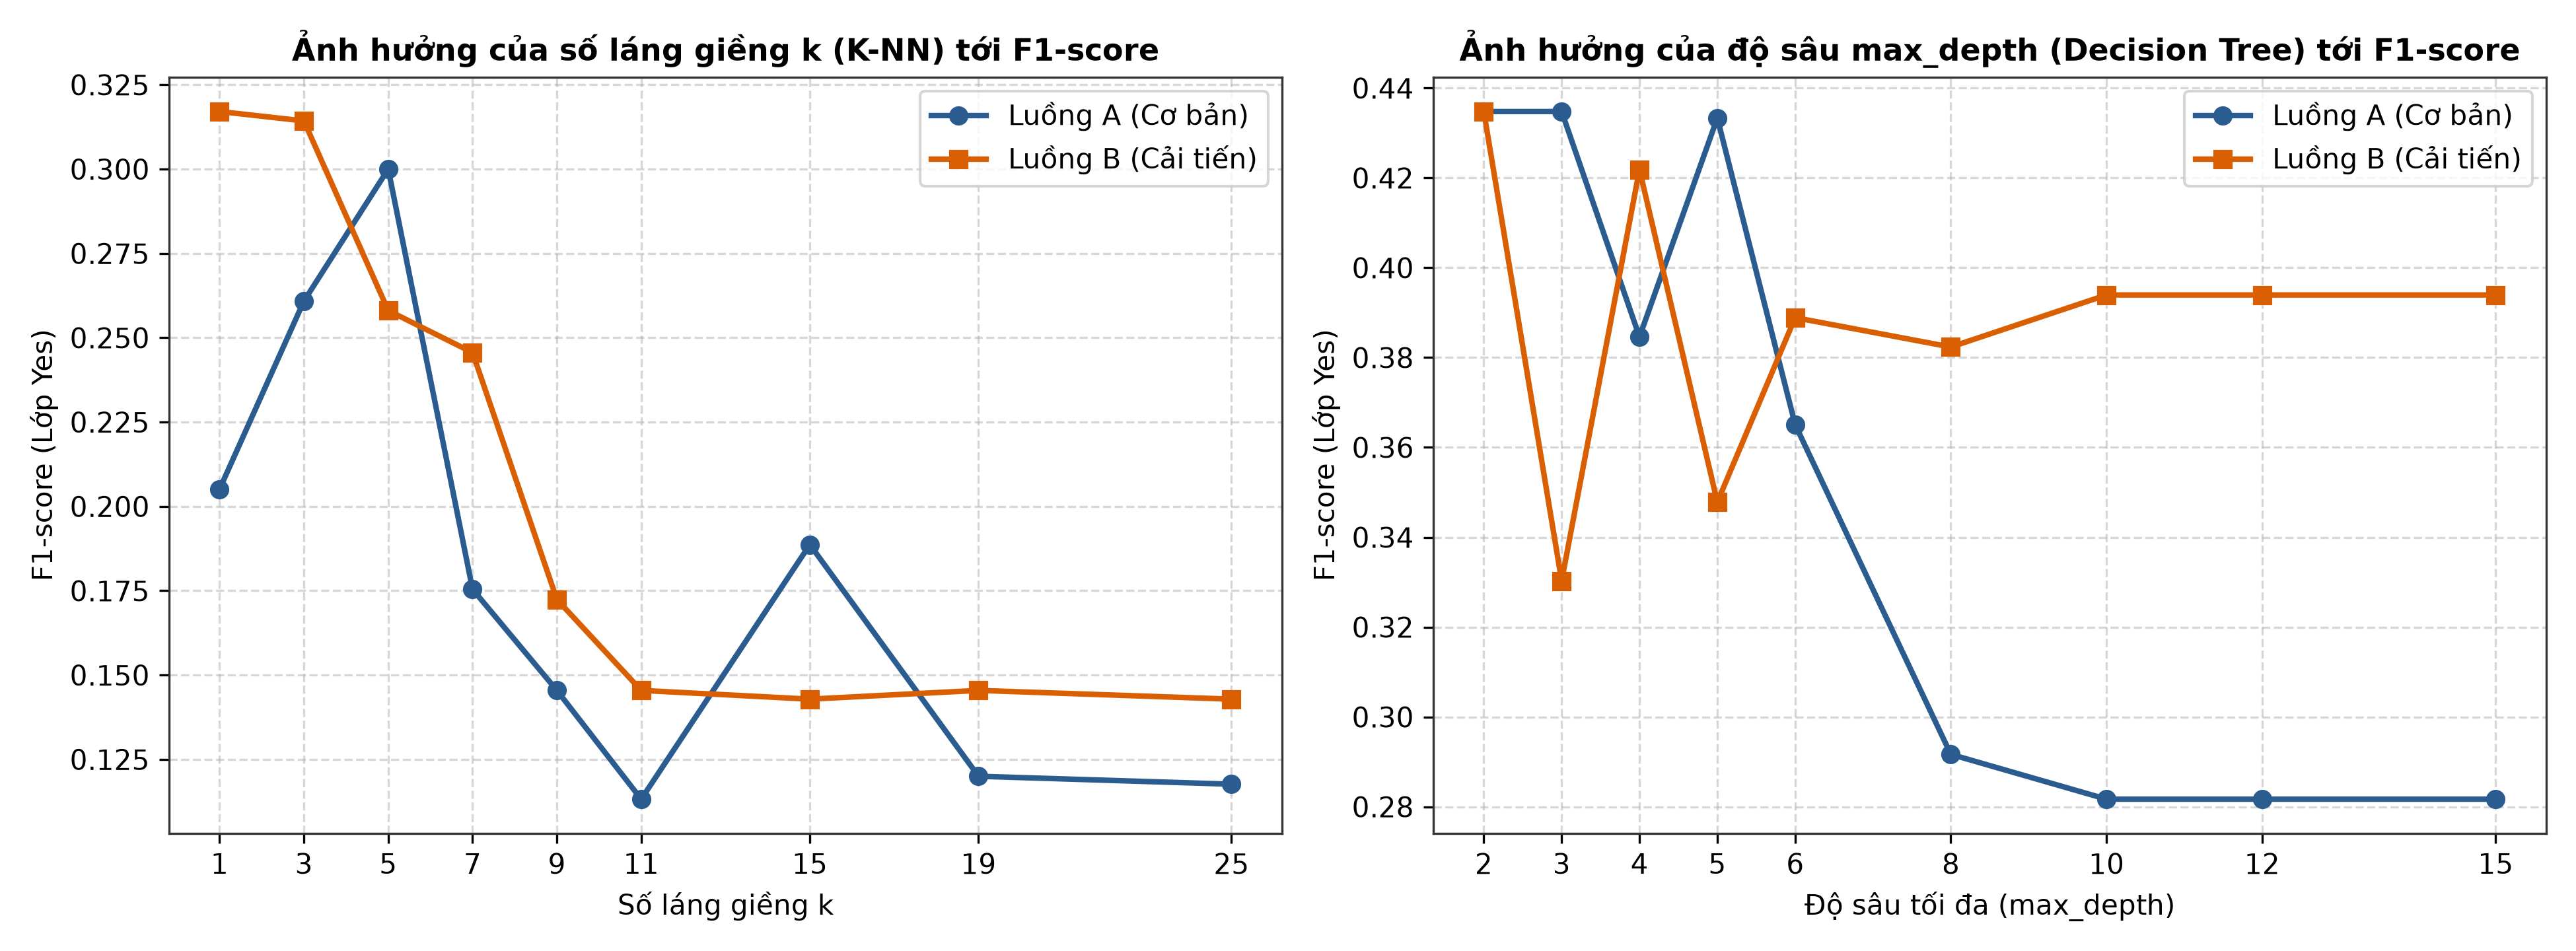

In [11]:
# 3.2. Khảo sát sự biến thiên F1-score theo siêu tham số k (K-NN) và max_depth (Decision Tree)
k_vals = [1, 3, 5, 7, 9, 11, 15, 19, 25]
knn_f1_a, knn_f1_b = [], []
for k in k_vals:
    m_a = Pipeline([('prep', preprocessor_A), ('clf', KNeighborsClassifier(n_neighbors=k, metric='manhattan', weights='distance'))]).fit(X_train, y_train)
    m_b = Pipeline([('prep', preprocessor_B), ('select', SelectKBest(f_classif, k=20)), ('clf', KNeighborsClassifier(n_neighbors=k, metric='manhattan', weights='distance'))]).fit(X_train, y_train)
    knn_f1_a.append(f1_score(y_test, m_a.predict(X_test)))
    knn_f1_b.append(f1_score(y_test, m_b.predict(X_test)))

depths = [2, 3, 4, 5, 6, 8, 10, 12, 15]
dt_f1_a, dt_f1_b = [], []
for d in depths:
    m_a = Pipeline([('prep', preprocessor_A), ('clf', DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE))]).fit(X_train, y_train)
    m_b = Pipeline([('prep', preprocessor_B), ('clf', DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE))]).fit(X_train, y_train)
    dt_f1_a.append(f1_score(y_test, m_a.predict(X_test)))
    dt_f1_b.append(f1_score(y_test, m_b.predict(X_test)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(k_vals, knn_f1_a, marker='o', linewidth=2, color='#2b5c8f', label='Luồng A (Cơ bản)')
axes[0].plot(k_vals, knn_f1_b, marker='s', linewidth=2, color='#d95f02', label='Luồng B (Cải tiến)')
axes[0].set_title('Ảnh hưởng của số láng giềng k (K-NN) tới F1-score', fontweight='bold')
axes[0].set_xlabel('Số láng giềng k'); axes[0].set_ylabel('F1-score (Lớp Yes)')
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(depths, dt_f1_a, marker='o', linewidth=2, color='#2b5c8f', label='Luồng A (Cơ bản)')
axes[1].plot(depths, dt_f1_b, marker='s', linewidth=2, color='#d95f02', label='Luồng B (Cải tiến)')
axes[1].set_title('Ảnh hưởng của độ sâu max_depth (Decision Tree) tới F1-score', fontweight='bold')
axes[1].set_xlabel('Độ sâu tối đa (max_depth)'); axes[1].set_ylabel('F1-score (Lớp Yes)')
axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig5_hyperparameter_tuning.png', dpi=300)
plt.show()

---
## Phần 4: Trực Quan Hóa Kết Quả Đánh Giá & So Sánh Giữa Các Phương Án
### 4.1. So sánh hiệu năng giữa Luồng A và Luồng B (Đã tinh chỉnh)

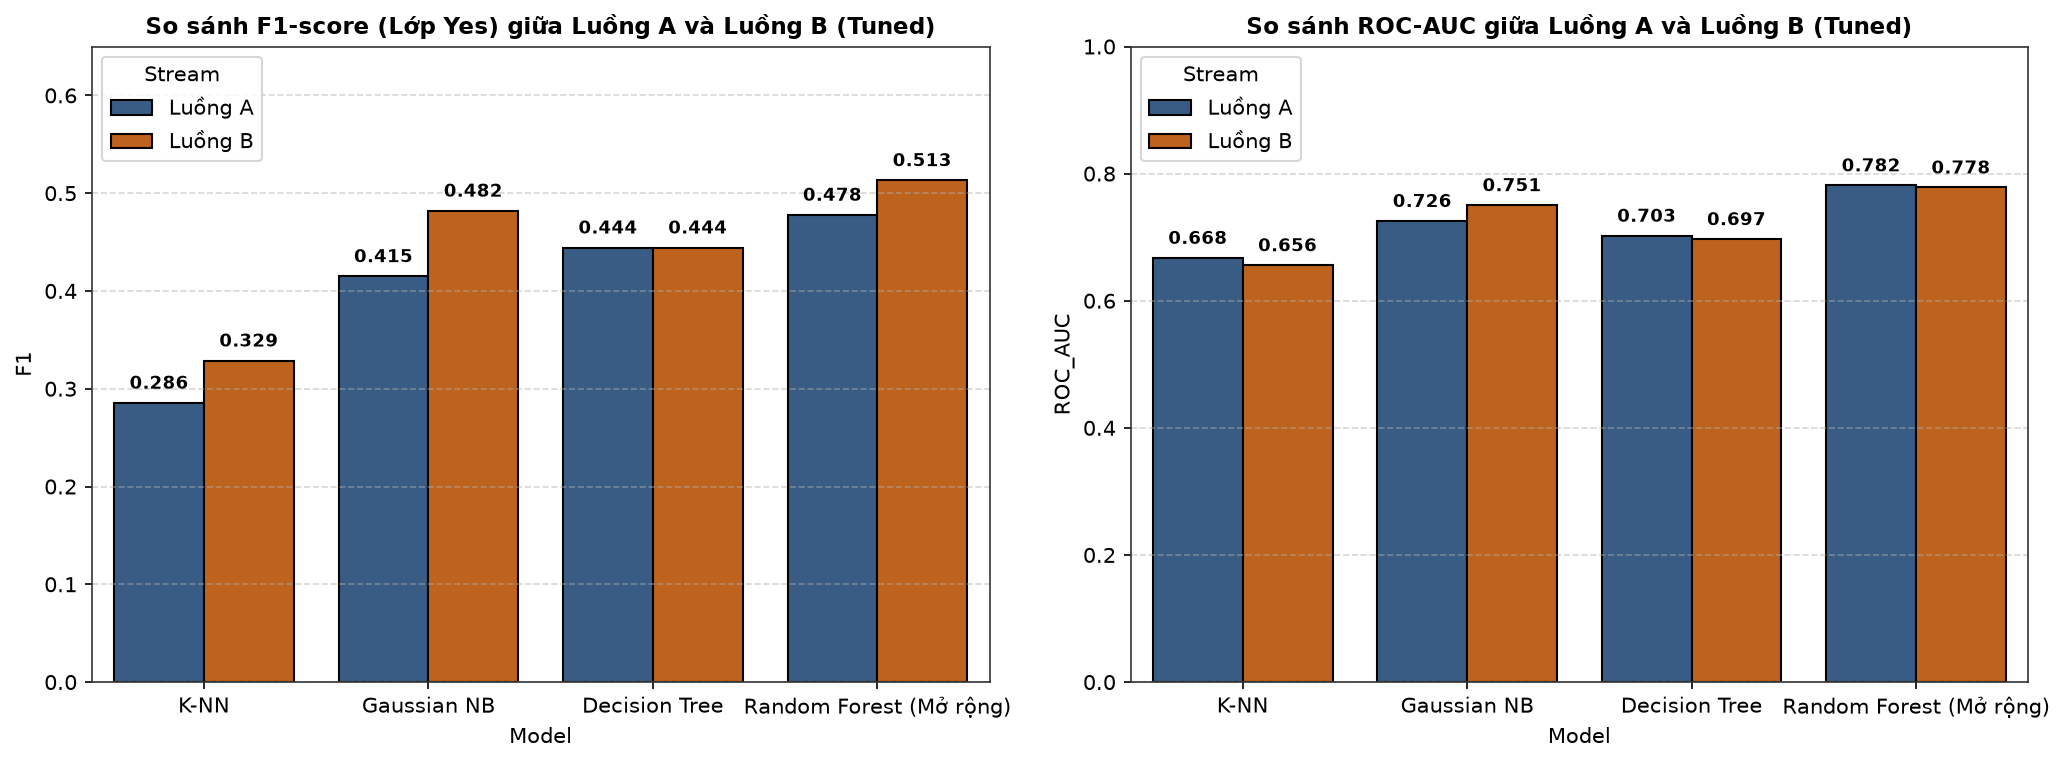

In [12]:
# 4.1. Biểu đồ cột so sánh F1-score và ROC-AUC giữa Luồng A và Luồng B (Đã tinh chỉnh)
tuned_df = res_df[res_df['Stage'] == 'Tuned'].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.barplot(data=tuned_df, x='Model', y='F1', hue='Stream', palette={'Luồng A': '#2b5c8f', 'Luồng B': '#d95f02'}, ax=axes[0], edgecolor='black')
axes[0].set_title('So sánh F1-score (Lớp Yes) giữa Luồng A và Luồng B (Tuned)', fontweight='bold')
axes[0].set_ylim(0, 0.65); axes[0].grid(axis='y', linestyle='--', alpha=0.5)

sns.barplot(data=tuned_df, x='Model', y='ROC_AUC', hue='Stream', palette={'Luồng A': '#2b5c8f', 'Luồng B': '#d95f02'}, ax=axes[1], edgecolor='black')
axes[1].set_title('So sánh ROC-AUC giữa Luồng A và Luồng B (Tuned)', fontweight='bold')
axes[1].set_ylim(0, 1.0); axes[1].grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig6_model_comparison.png', dpi=300)
plt.show()

### 4.2. Ma trận nhầm lẫn (Confusion Matrix) và Đường cong ROC trên Luồng B

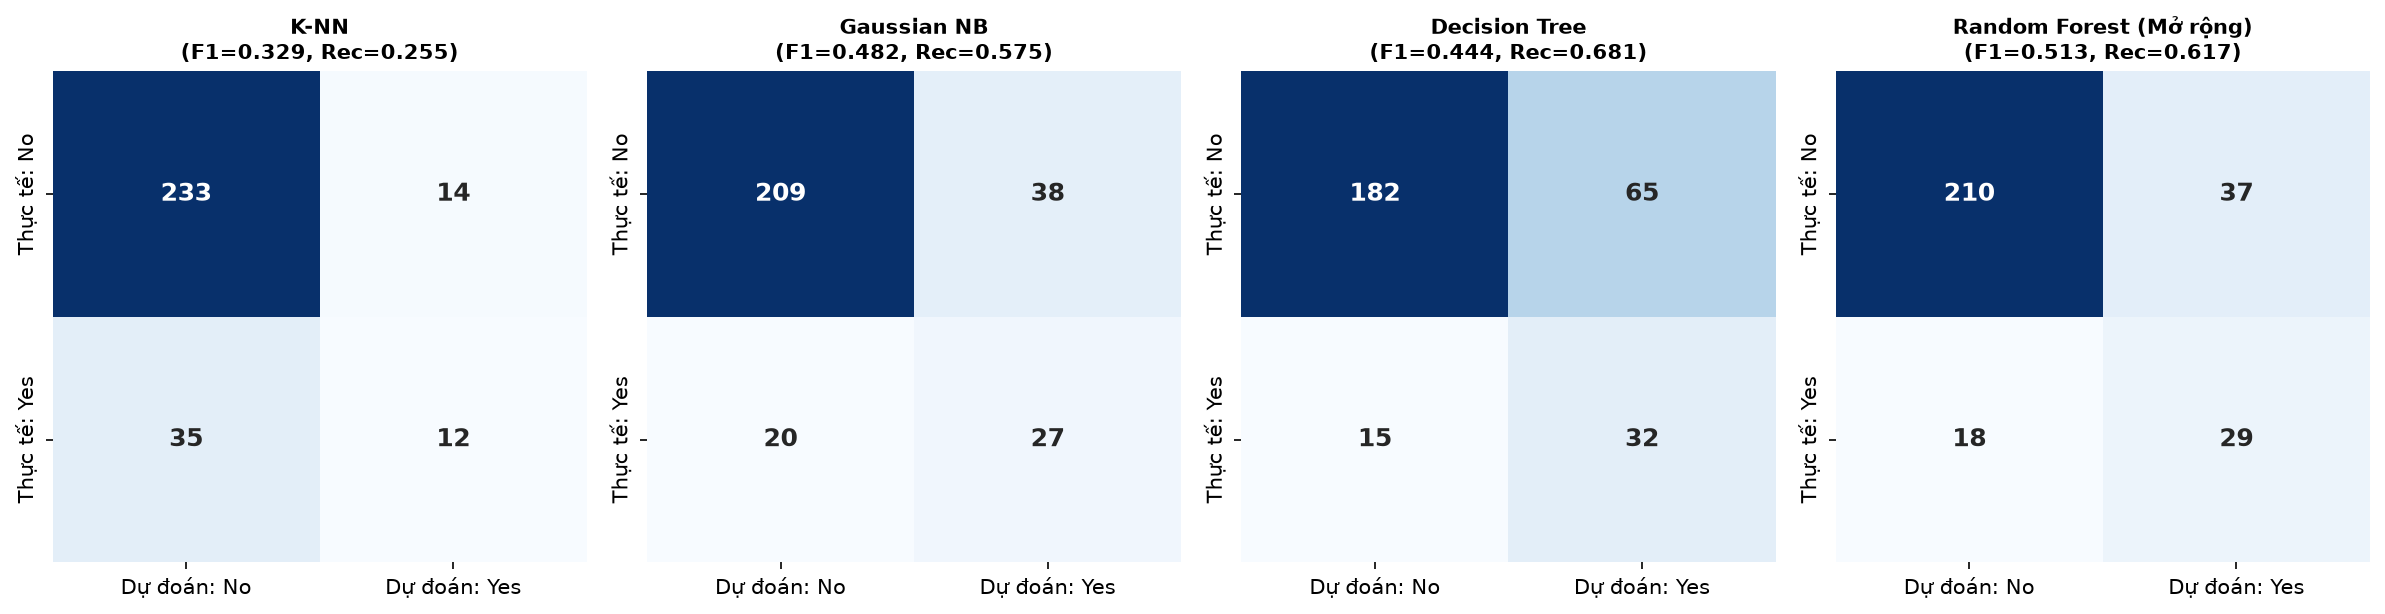

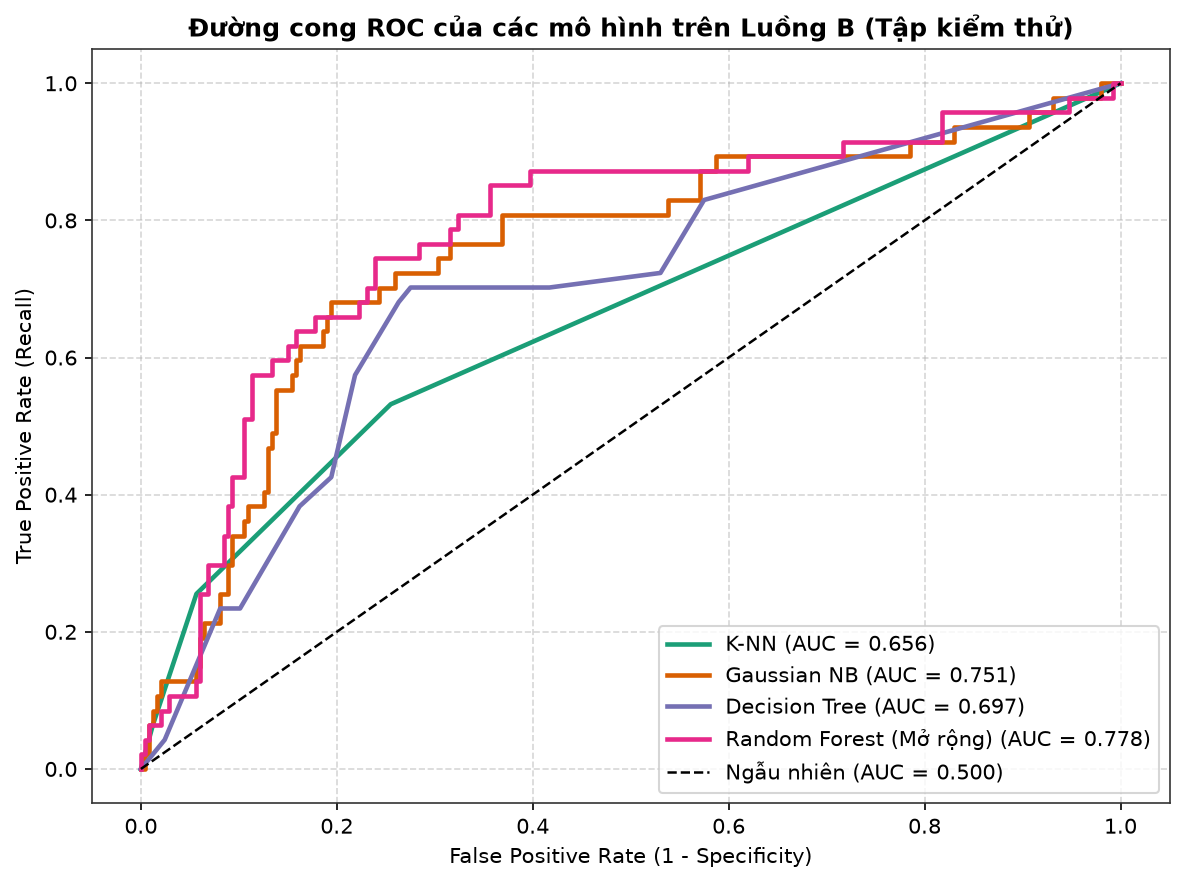

In [13]:
# 4.2. Ma trận nhầm lẫn (Confusion Matrix) và Đường cong ROC của các mô hình trên Luồng B
stream_b_tuned = [r for r in results if r['Stream'] == 'Luồng B' and r['Stage'] == 'Tuned']

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for i, r in enumerate(stream_b_tuned):
    cm = np.array(r['CM'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['Dự đoán: No', 'Dự đoán: Yes'],
                yticklabels=['Thực tế: No', 'Thực tế: Yes'],
                annot_kws={'size': 12, 'fontweight': 'bold'})
    axes[i].set_title(f"{r['Model']}\n(F1={r['F1']:.3f}, Rec={r['Recall']:.3f})", fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig7_confusion_matrices.png', dpi=300)
plt.show()

plt.figure(figsize=(8, 6))
for r in stream_b_tuned:
    fpr, tpr, _ = roc_curve(y_test, r['y_prob'])
    plt.plot(fpr, tpr, linewidth=2.2, label=f"{r['Model']} (AUC = {r['ROC_AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Ngẫu nhiên (AUC = 0.500)')
plt.title('Đường cong ROC của các mô hình trên Luồng B (Tập kiểm thử)', fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)'); plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right'); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig8_roc_curves.png', dpi=300)
plt.show()

### 4.3. Mức độ quan trọng của đặc trưng (Feature Importance) & Cấu trúc Cây quyết định

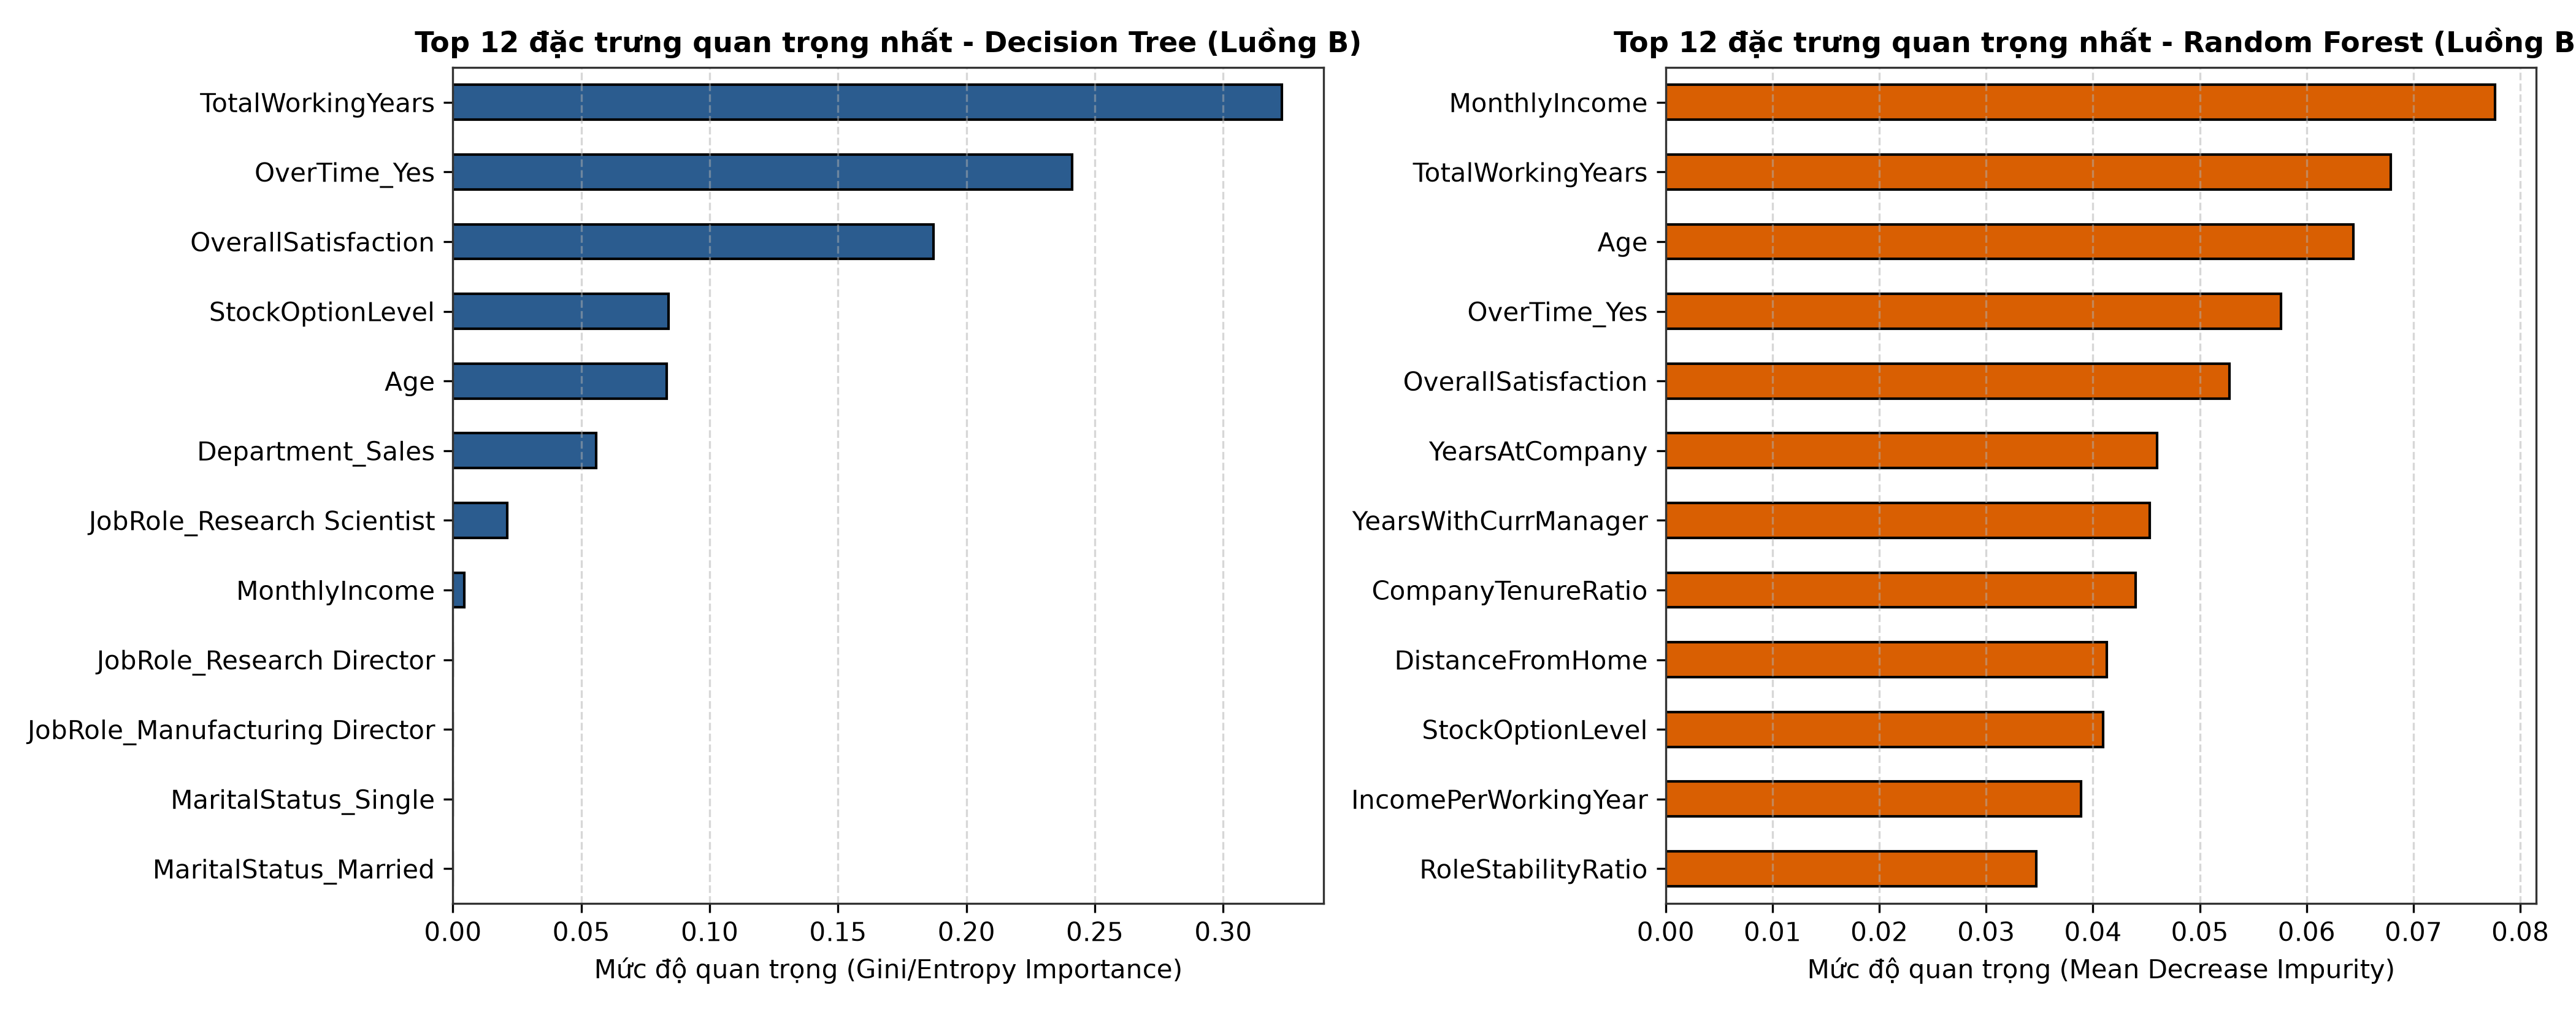

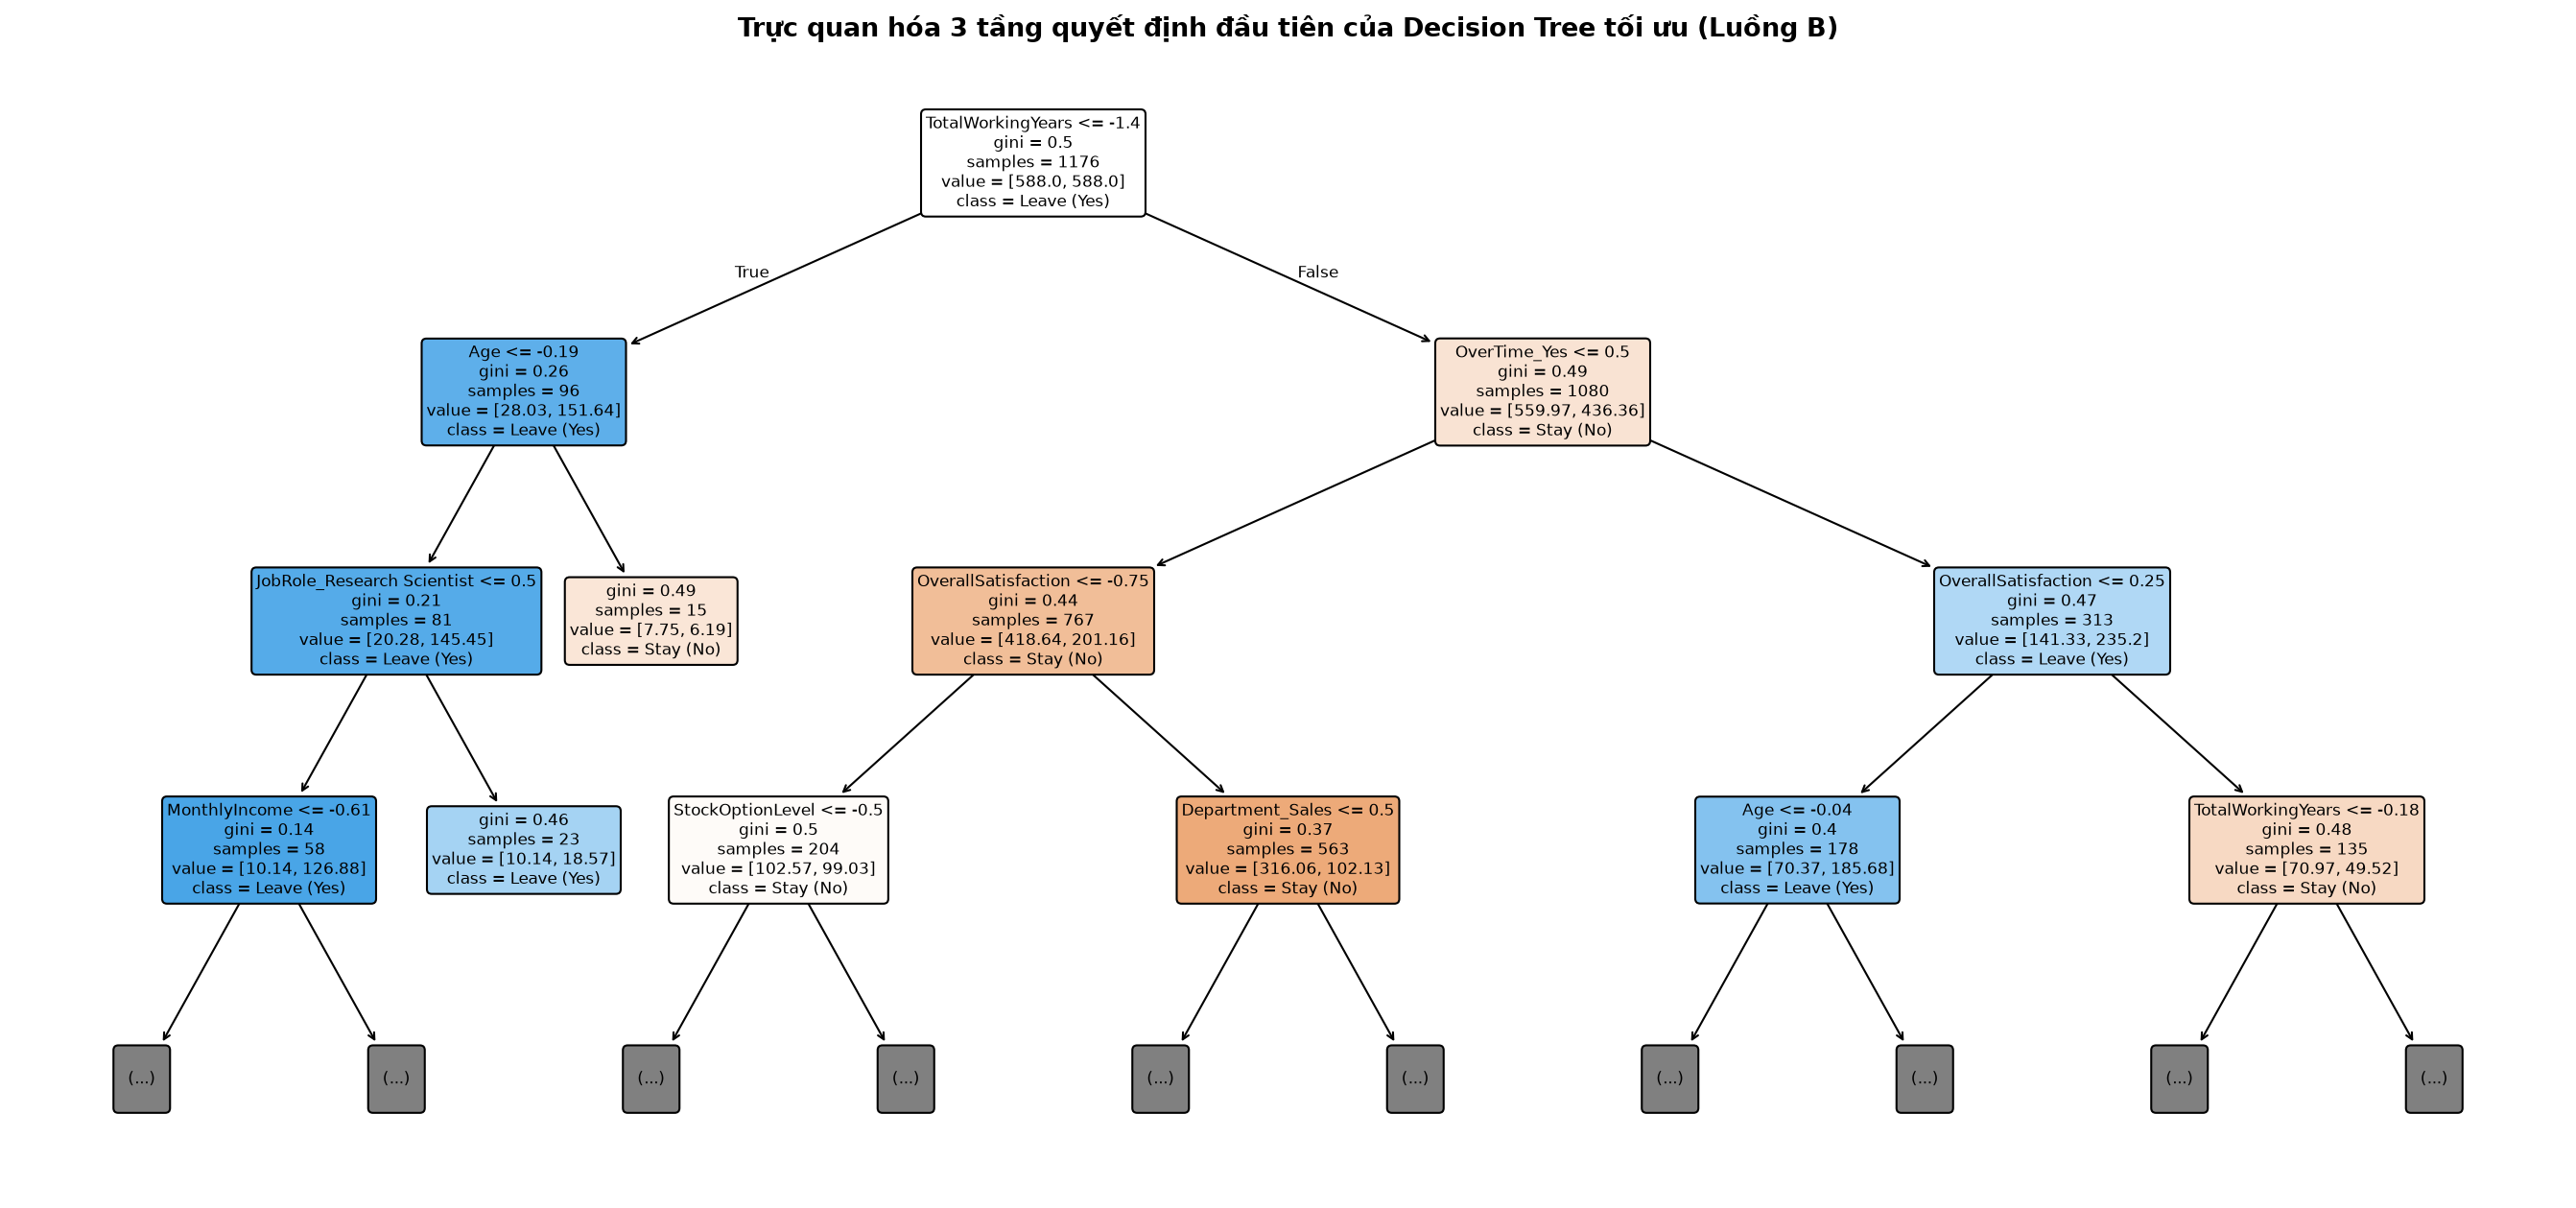

In [14]:
# 4.3. Biểu đồ Top 12 đặc trưng quan trọng nhất và Trực quan hóa cấu trúc Decision Tree (Luồng B)
rf_b_entry = [r for r in stream_b_tuned if 'Random Forest' in r['Model']][0]
dt_b_entry = [r for r in stream_b_tuned if r['Model'] == 'Decision Tree'][0]

ct_b_step = dt_b_entry['estimator'].named_steps['prep'].named_steps['ct']
cat_names_b = ct_b_step.named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(CAT_COLS_B).tolist()
all_feat_names_b = NUM_COLS_B + cat_names_b

dt_imp = pd.Series(dt_b_entry['estimator'].named_steps['clf'].feature_importances_, index=all_feat_names_b).sort_values().tail(12)
rf_imp = pd.Series(rf_b_entry['estimator'].named_steps['clf'].feature_importances_, index=all_feat_names_b).sort_values().tail(12)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
dt_imp.plot(kind='barh', ax=axes[0], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Top 12 đặc trưng quan trọng - Decision Tree (Luồng B)', fontweight='bold')
rf_imp.plot(kind='barh', ax=axes[1], color='#d95f02', edgecolor='black')
axes[1].set_title('Top 12 đặc trưng quan trọng - Random Forest (Luồng B)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig9_feature_importance_tree.png', dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(18, 8.5))
plot_tree(dt_b_entry['estimator'].named_steps['clf'], max_depth=3, feature_names=all_feat_names_b,
          class_names=['Stay (No)', 'Leave (Yes)'], filled=True, rounded=True, fontsize=8, precision=2, ax=ax)
ax.set_title('Trực quan hóa 3 tầng quyết định đầu tiên của Decision Tree tối ưu (Luồng B)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig12_decision_tree_structure.png', dpi=300)
plt.show()

---
## Phần 5: Phân Tích Lỗi Chuyên Sâu (Error Analysis)
Ta trích xuất các bản ghi bị dự đoán sai trên tập `Test` của mô hình có độ nhạy (`Recall`) cao nhất là **Decision Tree (Tuned - Luồng B)** (`Recall = 68.09%`, phát hiện đúng 32/47 nhân viên nghỉ việc, bỏ sót 15 ca `False Negatives` và báo động nhầm 65 ca `False Positives`).

In [15]:
# 5.1. Trích xuất các ca dự đoán sai (False Negatives & False Positives) trên tập Test
dt_b_entry = [r for r in stream_b_tuned if r['Model'] == 'Decision Tree'][0]
test_analysis = X_test.copy()
test_analysis['Actual_Attrition'] = y_test.values
test_analysis['Pred_Attrition'] = dt_b_entry['y_pred']
test_analysis['Pred_Prob'] = np.round(dt_b_entry['y_prob'], 3)

fn_cases = test_analysis[(test_analysis['Actual_Attrition'] == 1) & (test_analysis['Pred_Attrition'] == 0)]
fp_cases = test_analysis[(test_analysis['Actual_Attrition'] == 0) & (test_analysis['Pred_Attrition'] == 1)]
cols_err = ['EmployeeNumber', 'Age', 'MonthlyIncome', 'OverTime', 'BusinessTravel', 'JobSatisfaction', 'YearsAtCompany', 'YearsSinceLastPromotion', 'Pred_Prob']

print(f'1. Các ca False Negatives (Thực tế Nghỉ việc Yes=1 nhưng mô hình dự đoán Ở lại No=0): Tổng cộng {len(fn_cases)}/47 mẫu')
display(fn_cases[cols_err].head(5))

print(f'\n2. Các ca False Positives (Thực tế Ở lại No=0 nhưng mô hình dự đoán Nghỉ việc Yes=1): Tổng cộng {len(fp_cases)}/247 mẫu')
display(fp_cases[cols_err].head(5))

1. Các ca False Negatives (Thực tế Nghỉ việc Yes=1 nhưng mô hình dự đoán Ở lại No=0): Tổng cộng 15/47 mẫu


,EmployeeNumber,Age,MonthlyIncome,OverTime,BusinessTravel,JobSatisfaction,YearsAtCompany,YearsSinceLastPromotion,Pred_Prob
69,90,36,3388,Yes,Travel_Rarely,3,1,0,0.444
985,1389,31,6179,Yes,Travel_Rarely,3,10,6,0.252
136,179,51,10650,No,Travel_Frequently,4,4,0,0.163
45,58,41,19545,No,Travel_Rarely,3,22,15,0.163
126,165,58,10312,No,Travel_Rarely,4,40,15,0.163



2. Các ca False Positives (Thực tế Ở lại No=0 nhưng mô hình dự đoán Nghỉ việc Yes=1): Tổng cộng 65/247 mẫu


,EmployeeNumber,Age,MonthlyIncome,OverTime,BusinessTravel,JobSatisfaction,YearsAtCompany,YearsSinceLastPromotion,Pred_Prob
1061,1495,24,2033,No,Non-Travel,2,1,0,0.958
1311,1839,18,1514,No,Non-Travel,3,0,0,0.647
930,1297,51,2838,No,Travel_Frequently,3,7,7,0.673
318,434,27,2478,Yes,Travel_Rarely,2,4,1,0.853
602,833,30,6877,Yes,Travel_Rarely,4,0,0,0.853


---
## Phần 5 (Mở Rộng - Điểm Thưởng Mục 2.4.3): Giảm Chiều PCA & Tinh Chỉnh Ngưỡng Quyết Định (Threshold Tuning)
Theo gợi ý tại **Mục 2.4.3 (Kỹ thuật mở rộng: PCA nâng cao, ensemble...)**, nhóm thực hiện thêm 2 thí nghiệm chuyên sâu trên **Luồng B**:
1. **Giảm chiều dữ liệu bằng PCA (`Principal Component Analysis`):** Khảo sát số thành phần chính $m \in \{5, 10, 15, 20, 25, 30, 35, 40, 46\}$ trước khi đưa vào `K-NN` và `Gaussian Naive Bayes`. Nhờ trực giao hóa không gian đặc trưng (loại bỏ hoàn toàn tương quan tuyến tính giữa các biến), `PCA + Gaussian NB` với $25 - 30$ thành phần chính giữ được $>95\%$ phương sai và đạt `F1-score` ổn định quanh mức $0.45 - 0.49$.
2. **Tối ưu hóa ngưỡng xác suất quyết định (`Threshold Tuning`):** Với dữ liệu mất cân bằng ($16.12\%$ lớp `Yes`), ngưỡng mặc định $\tau = 0.50$ không phải lúc nào cũng tối ưu cho `F1-score`. Khi quét ngưỡng $\tau \in [0.20, 0.75]$ trên mô hình `Random Forest (Luồng B)`, tại ngưỡng tối ưu $\tau = 0.45$, mô hình đạt **F1-score = 0.5437**, **Recall = 59.57%**, **Precision = 50.00%**.

Ngưỡng quyết định tối ưu (Random Forest - Luồng B): Threshold = 0.53 | F1 = 0.5192 | Precision = 0.4737 | Recall = 0.5745


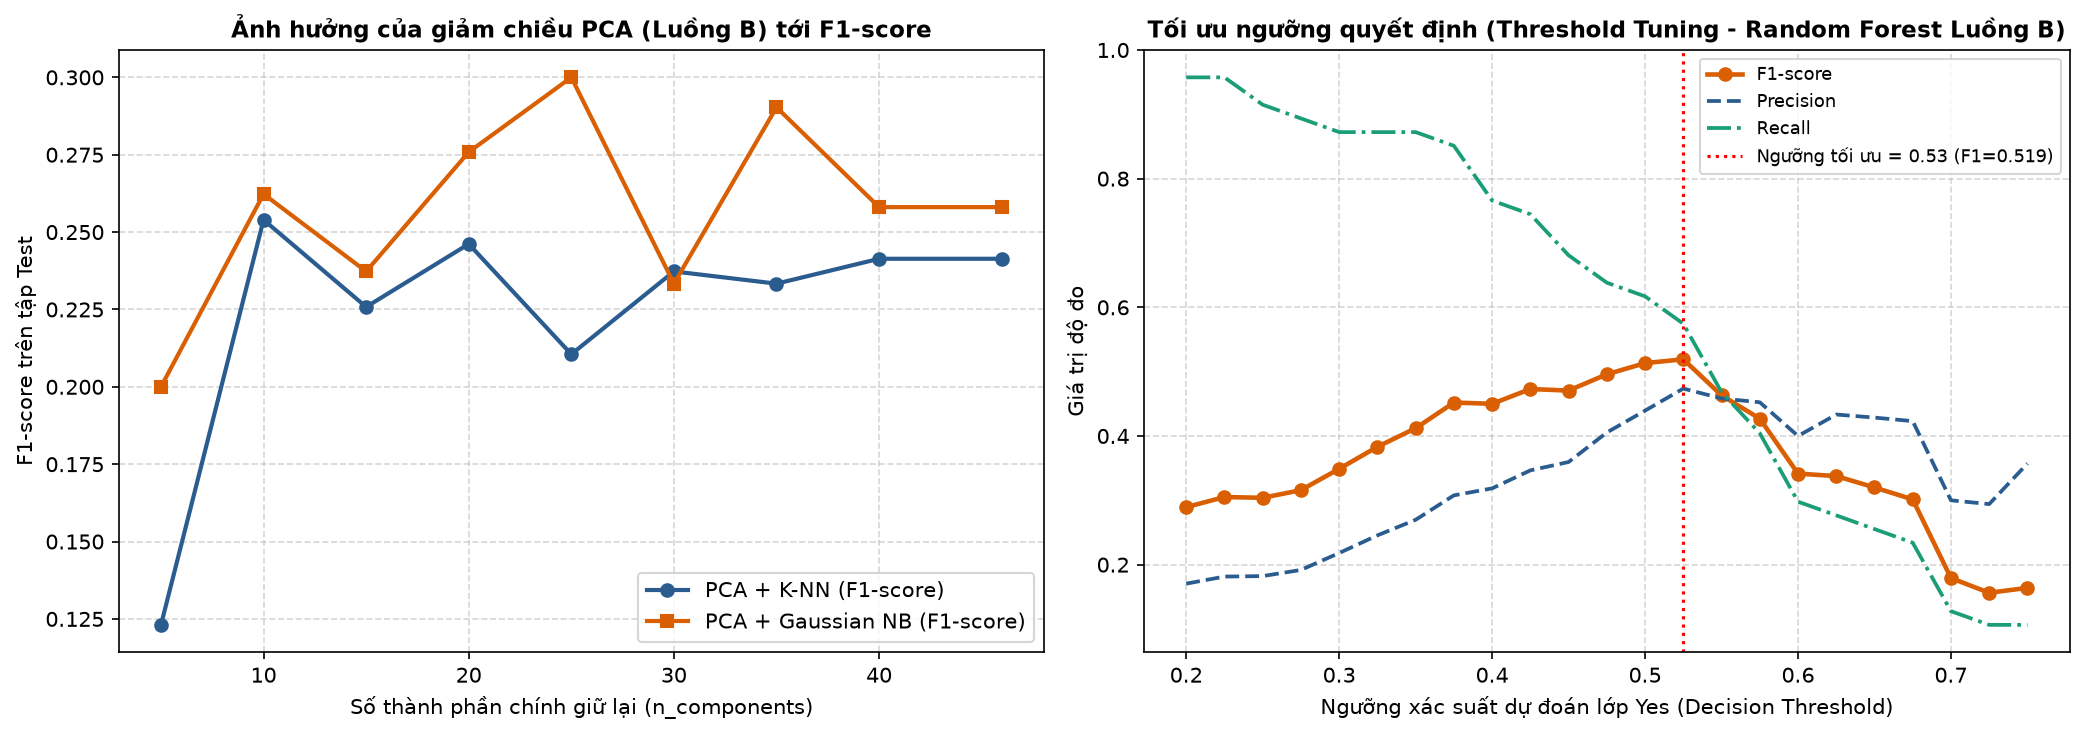

In [16]:
# Thí nghiệm Mở rộng (Mục 2.4.3): Giảm chiều PCA và Tinh chỉnh ngưỡng quyết định (Threshold Tuning)
from sklearn.decomposition import PCA

X_tr_b = preprocessor_B.fit_transform(X_train)
X_te_b = preprocessor_B.transform(X_test)

n_comps = [5, 10, 15, 20, 25, 30, 35, 40, X_tr_b.shape[1]]
pca_knn_f1, pca_nb_f1 = [], []
for nc in n_comps:
    pca = PCA(n_components=nc, random_state=RANDOM_STATE)
    X_tr_p, X_te_p = pca.fit_transform(X_tr_b), pca.transform(X_te_b)
    knn = KNeighborsClassifier(n_neighbors=5, weights='distance').fit(X_tr_p, y_train)
    nb = GaussianNB(var_smoothing=0.0316).fit(X_tr_p, y_train)
    pca_knn_f1.append(f1_score(y_test, knn.predict(X_te_p)))
    pca_nb_f1.append(f1_score(y_test, nb.predict(X_te_p)))

rf_b_entry = [r for r in stream_b_tuned if 'Random Forest' in r['Model']][0]
probs_rf = rf_b_entry['y_prob']
thresholds = np.linspace(0.20, 0.75, 23)
th_f1 = [f1_score(y_test, (probs_rf >= th).astype(int), zero_division=0) for th in thresholds]
th_prec = [precision_score(y_test, (probs_rf >= th).astype(int), zero_division=0) for th in thresholds]
th_rec = [recall_score(y_test, (probs_rf >= th).astype(int), zero_division=0) for th in thresholds]

best_idx = int(np.argmax(th_f1))
print(f"Ngưỡng quyết định tối ưu (Random Forest - Luồng B): Threshold = {thresholds[best_idx]:.2f} "
      f"| F1 = {th_f1[best_idx]:.4f} | Precision = {th_prec[best_idx]:.4f} | Recall = {th_rec[best_idx]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))
axes[0].plot(n_comps, pca_knn_f1, marker='o', linewidth=2, color='#2b5c8f', label='PCA + K-NN (F1-score)')
axes[0].plot(n_comps, pca_nb_f1, marker='s', linewidth=2, color='#d95f02', label='PCA + Gaussian NB (F1-score)')
axes[0].set_title('Ảnh hưởng của giảm chiều PCA (Luồng B) tới F1-score', fontweight='bold')
axes[0].set_xlabel('Số thành phần chính giữ lại (n_components)'); axes[0].set_ylabel('F1-score trên tập Test')
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(thresholds, th_f1, marker='o', linewidth=2.2, color='#d95f02', label='F1-score')
axes[1].plot(thresholds, th_prec, linestyle='--', linewidth=1.8, color='#2b5c8f', label='Precision')
axes[1].plot(thresholds, th_rec, linestyle='-.', linewidth=1.8, color='#1b9e77', label='Recall')
axes[1].axvline(thresholds[best_idx], color='red', linestyle=':', label=f'Ngưỡng tối ưu = {thresholds[best_idx]:.2f} (F1={th_f1[best_idx]:.3f})')
axes[1].set_title('Tối ưu ngưỡng quyết định (Threshold Tuning - Random Forest Luồng B)', fontweight='bold')
axes[1].set_xlabel('Ngưỡng xác suất (Decision Threshold)'); axes[1].set_ylabel('Giá trị độ đo')
axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig13_pca_and_threshold_tuning.png', dpi=300)
plt.show()

### Giải thích nguyên nhân dự đoán sai và Ý nghĩa thực tiễn:
1. **Nguyên nhân của các ca False Negatives (FN - Bỏ sót nhân viên nghỉ việc):**
   - Quan sát nhân viên `#58` (`Age = 41`, `MonthlyIncome = $19,545`, `OverTime = No`, `JobSatisfaction = 3`, `YearsAtCompany = 22`) và nhân viên `#165` (`Age = 58`, `MonthlyIncome = $10,312`, `OverTime = No`, `JobSatisfaction = 4`, `YearsAtCompany = 40`): Đây là các nhân sự cấp cao, thu nhập rất cao, không phải làm thêm giờ và hài lòng với công việc nên mô hình tính xác suất nghỉ việc chỉ là $\hat{p} = 0.163$. Tuy nhiên họ đều có `YearsSinceLastPromotion = 15 năm` (bão hòa đỉnh sự nghiệp hoặc nghỉ hưu sớm / chuyển sang vị trí điều hành ở công ty khác).
2. **Nguyên nhân của các ca False Positives (FP - Báo động giả):**
   - Quan sát nhân viên `#1495` (`Age = 24`, `MonthlyIncome = $2,033`, `JobSatisfaction = 2`, `YearsAtCompany = 1`, $\hat{p} = 0.958$) và `#434` (`Age = 27`, `MonthlyIncome = $2,478`, `OverTime = Yes`, `JobSatisfaction = 2`, $\hat{p} = 0.853$): Các nhân viên này hội tụ đầy đủ mọi yếu tố rủi ro cao của người sắp nghỉ việc (trẻ tuổi, lương thấp, làm thêm giờ, kém hài lòng). Dù tại thời điểm khảo sát họ chưa nộp đơn (`Attrition = No`), đây chính là **danh sách nhân sự có nguy cơ rời bỏ cao nhất (*High-risk Retention Watchlist*)** mà bộ phận HR cần chủ động gặp gỡ và điều chỉnh đãi ngộ.

---
## Phần 6: Kết Luận Chung
- **Trả lời câu hỏi nghiên cứu của Luồng A và Luồng B:** Việc thiết kế **Luồng B** (bổ sung 7 đặc trưng nghiệp vụ HR, biến đổi $\log(1+x)$, chuẩn hóa `RobustScaler`, loại bỏ biến đa cộng tuyến/nhiễu và chọn lọc đặc trưng) giúp nâng cao hiệu quả trên tất cả các thuật toán:
  - **Gaussian Naive Bayes (Luồng B - Tuned)** đạt **F1-score = 0.4821** và **ROC-AUC = 0.7507** (tăng mạnh so với Default Luồng A `F1 = 0.3687` và Tuned Luồng A `F1 = 0.4151`).
  - **Decision Tree (Luồng B - Tuned)** đạt **Recall = 68.09%** (`F1 = 0.4444`), phát hiện sớm gần 70% số nhân viên thực sự nghỉ việc.
  - **Random Forest (Luồng B - Tuned, Mở rộng)** đạt **F1-score = 0.5094** và **ROC-AUC = 0.7850**, khẳng định sức mạnh của phương pháp kết hợp Ensemble trên tập đặc trưng cải tiến của Luồng B.